## Практическое домашнее задание 2. Градиентный спуск своими руками

### Общая информация

Дата выдачи: 16.10.2026

Мягкий дедлайн: 16.11.2026 23:59 MSK

Жесткий дедлайн: 23.11.2026 23:59 MSK


### Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). **Максимально допустимая оценка за работу — 10 баллов.**

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке. Также оценка может быть снижена за плохо читаемый код и плохо считываемые диаграммы.

Все ответы должны сопровождаться кодом или комментариями о том, как они были получены.

Для удобства проверки самостоятельно посчитайте свою максимальную оценку (исходя из набора решенных задач) и укажите ниже.

**Оценка**: 10


### О задании

В данном задании необходимо реализовать обучение линейной регрессии с помощью различных модификаций градиентного спуска. В файле `descents.py` вам нужно будет реализовать несколько классов для различных вариаций градиентного спуска, а именно:
* `VanillaGradientDescent`
* `StochasticGradientDescent`
* `SAGDescent`
* `MomentumDescent`
* `Adam`


В файле `linear_regression.py` вам необходимо будет реализовать класс `CustomLinearRegression` для обучения линейной регрессии (и, разумеется, предсказания целевой переменной на основе обученной модели).


### Про предложенную архитектуру

Предложенная вам архитектура шаблонов написана по принципам SOLID: основная ее идея в том, что вы сможете использовать различные лоссы и оптимизаторы с одним и тем же кодом прочих классов, никак не изменяя и не переписывая методы классов, которые с оптимизаторами и лоссом взаимодействуют. Мы добиваемся этого при помощи выделения интерфейсов (в Python мы достигаем этого при помощи абстрактных классов, см дальше в заданиях) и выделения зон ответственности каждого класса.

Глобально в нашей архитектуре всего 4 интерфейса (некоторые из которых на самом деле сразу concrete классы), каждый из которых порождает одно семейство:
- `interfaces.LossFunction`
  - Классы, имплементирующие этот интерфейс, отвечают за одну конкретную функцию потерь, используемую при обучении, и всё, что меняется вместе с ней при её замене: подсчёт лосса, подсчет градиента и аналитическое решение (если есть, то добавляется в интерфейс соответствующим mixin-ом).
- `interfaces.LinearRegressionInterface`
  - Интерфейс обертки для модели линейной регрессии, контейнер, содержащий составные части (лосс-функцию и оптимизатор) и использующий их для выполнения содержательной работы.
- `interfaces.LearningRateSchedule`
 - Простенькое семейство расписаний, определяющих шаг обучения для каждой итерации
- `interfaces.AbstractOptimizer`.
  -  Классы, имплементирующие этот интерфейс, имплементируют конкретный алгоритм оптимизации и всё, что происходит в его процессе. Пользуются обёрткой линейной регрессии для доступа к данным и вызова расчетов, чтобы не зависеть напрямую от конкретных функций потерь и шедулеров шага обучения.

Концепция передачи маленьких объектов, отвечающих за свою маленькую зону ответственности внутрь более сложного объекта для выполнения ими составных частей работы называется Dependency Injection, и работает как раз за счет выделения зоны ответственности и опоры на интерфейс вместо реализации.

Посмотрите на код `linear_regression.CustomLinearRegression`: она принимает в себя объекты с интерфейсами `LossFunction` и `AbstractOptimizer`, а в `descents.BaseDescent` как уточнении интерфейса абстрактного оптимизатора до итеративных оптимизаторов видно, что он в свою очередь принимает при инициализации объект шедулера шага обучения.

Благодаря этому, код, который использует эти классы, может по очереди:
- Инициализировать нужный шедулер с нужными параметрами для задания шага обучения
- Иницализировать оптимизатор, задав ему нужные параметры процесса и передав готовый шедулер
- Инициализировать класс линейной регрессии нужной под задачу функцией потерь и уже готовым оптимизатором.
- Запустить процесс обучения

И на любом этапе можно использовать другой объект с подходящим интерфейсом, и всё будет работать!


**В ходе выполнения этой домашки вы наполните все эти семейства классов различными имплементациями и будете менять их на ходу как перчатки!**

Более подробно про наследование классов в Python можно прочитать здесь:
* Наследование: https://docs.python.org/3/tutorial/classes.html#inheritance
* Абстрактные классы: https://docs.python.org/3/library/abc.html



## Задание 1. Линейная регрессия  (1 балл)

### Градиент функции потерь MSE

### Задание 1.0. Градиент MSE в матричном виде (0.3 балла).

Напомним, что функция потерь MSE записывается как:

$$
    Q(w) = \frac{1}{\ell} \sum \limits_{i = 1}^\ell (y_i - \langle x_i, w \rangle)^2 = \frac{1}{\ell} \| X w - y \|^2
$$

где $\ell$ – количество объектов в выборке, $X \in \mathbb{R}^{\ell \times d}$ – матрица "объект-признак", а $y \in \mathbb{R}^\ell$ – целевая переменная. Через $x_i$ обозначается $i$-ая строчка матрицы $X$, отвечающая за $i$-й объект выборки.

- **Выпишите ниже градиент для функции потерь MSE в матричном виде.**

**Решение:**

$\nabla_w Q(w)=\frac{2}{\ell}X^T(Xw-y)$.


- **Имплементируйте методы `MSELoss.loss`, `MSELoss.gradient`**





### Задание 1.1 Аналитическое решение и `CustomLinearRegression` (0.7 балла)

Перед тем, как мы углубимся в итеративные методы оптимизации, давайте вспомним, что для ряда функций потерь существует и аналитическое решение. Давайте сперва вспомним, как оно выглядит для MSE.

- **Выведите формулу оптимальных $w$ в задаче минимизации MSE, и запишите её ниже.**

- **Имплементируйте подсчет этого решения в `MSELoss._plain_analytic_solution`**

$$\text{MSE} = \| X w - y \|^2$$
$$X^T(Xw-y)=0 \Rightarrow X^TXw=X^Ty \Rightarrow w=(X^TX)^{-1}X^Ty.$$

При вырожденной матрице используем псевдообратную: $w=X^+y$.

**Вопрос**: Как мы помним, у аналитического решения есть минусы - какие?

**Ответ**: Формирование $X^TX$ требует $O(nd^2)$ операций, решение системы требует $O(d^3)$ и $O(d^2)$ памяти. При мультиколлинеарности обратной матрицы нет, а плохая обусловленность усиливает численные ошибки.

Теперь прокинем это решение в наш класс линейной регрессии, чтобы получше разобраться в архитектуре.


- **Допишите класс `descents.AnalyticSolutionOptimizer`**
- **Допишите класс `CustomLinearRegression`**
  - В нем на текущем этапе нужно имплементировать все методы: `fit` и `predict` вам понадобятся прямо сейчас, а `compute_gradients` и `compute_loss` в следующей части.

Помните, про разделение ответственности классов!

За контроль процесса обучения отвечает оптимизатор, а объект линейной регрессии по факту выступает точкой входа, контейнером для данных и способом доступа к вычислениям, на основе которых оптимизатор принимает решения (e.g. значение антиградиента в точке весов).

При этом сам по себе оптимизатор должен быть универсален, в нем никак не должны содержаться детали, связанные с конкретными функциями потерь, все необходимое от них он может получить через `self.model`.

Аналогично, класс линейной регрессии тоже должен быть универсальным и готовым к работе с любыми лоссами и оптимизаторами, исполняющими заявленный интерфейс. Здесь применена dependency injection, и вы должны грммотно ее поддержать в своей имплементации. Аналогично, все, что вам может быть нужно от функций потерь, вы можете получить при помощи обращения к переданному объекту.

In [1]:
import numpy as np
from sklearn.linear_model import LinearRegression
from linear_regression import MSELoss, CustomLinearRegression, AnalyticSolutionOptimizer

np.random.seed(42)
num_objects = 100
dimension = 5

x = np.random.rand(num_objects, dimension)
y = np.random.rand(num_objects)

In [2]:
from sklearn.metrics import mean_squared_error as mse
import sklearn

sklearn_linreg = sklearn.linear_model.LinearRegression(fit_intercept=False)
sklearn_linreg.fit(x, y)
print("Sklearn MSE", mse(sklearn_linreg.predict(x), y))

your_linreg = CustomLinearRegression(AnalyticSolutionOptimizer(), loss_function=MSELoss())
your_linreg.fit(x, y)
print("Your MSE", mse(your_linreg.predict(x), y))

assert abs(mse(your_linreg.predict(x), y) - mse(sklearn_linreg.predict(x), y)) < 1e-12, "Не повезло, попробуйте еще раз"

Sklearn MSE 0.10169921635801295
Your MSE 0.10169921635801293


Давайте сделаем задание немного прикольнее и изменим одну из колонок. Как мы знаем, полная мультиколлинеарность запрещает нам пользоваться аналитическим решением, но `sklearn` по какой-то причине это обходит, хмм

In [3]:
x[:, 3] = x[:, 2] + x[:, 4]

In [4]:
sklearn_linreg = sklearn.linear_model.LinearRegression(fit_intercept=False)
sklearn_linreg.fit(x, y)
print("Sklearn MSE", mse(sklearn_linreg.predict(x), y))

your_linreg = CustomLinearRegression(AnalyticSolutionOptimizer(), loss_function=MSELoss())
your_linreg.fit(x, y)
print("Your MSE", mse(your_linreg.predict(x), y))

Sklearn MSE 0.11733131419547085
Your MSE 0.11733131419547085


Ваша задача - понять, как можно сделать так, чтобы аналитическое решение работало всегда, вне зависимости от матрицы X. Как оказывается, это можно сделать, если воспользоваться SVD разложением. Для имплементации воспользуйтесь `scipy.sparse.linalg.svds`.

- Выведите через SVD формулу оптимальных $w$ в задаче минимизации MSE.

- Имплементируйте подсчет этого решения в `MSELoss._svd_analytic_solution`
    - Мир итерационных агоритмов причудлив. Если вы посмотрите на опции солверов svds, то увидите, что возможности вычислить точно все сингулярные числа вам не дают (propack рандомизированный и даст вам неточные ответы). Используйте стандартный солвер, выставьте максимальную доступную точность.

- Ответьте на **вопрос на засыпку**. Вообще говоря, в ряде случаев (например в нашем), даже такая неабсолютная на первый взгляд точность все равно позволяет получить точное решение задачи. Обоснуйте, почему? Как называется такой вид SVD? Какого минимального числа сингулярных чисел с вероятностью 1 будет достаточно в нашем случае для получения точного решения? Обоснуйте, почему.


$$\text{X} = \underset{n\times m}{\mathrm{U}} \ \underset{m\times m}{\mathrm{\Sigma}} \ \underset{m\times k}{\mathrm{V^T}}$$
$$w=X^+y=V_r\Sigma_r^{-1}U_r^Ty.$$

**Ответ**: Это компактное SVD ранга $r$: нулевые сингулярные значения не нужны. После замены столбца ранг равен 4 с вероятностью 1, поэтому достаточно четырёх ненулевых сингулярных значений. Остальные четыре случайных столбца линейно независимы почти наверное. При полном ранге реализация восстанавливает недостающий компонент из остатка ранга 1.

Для ARPACK задано `tol=0`, то есть машинная точность: [документация SciPy](https://docs.scipy.org/doc/scipy/reference/sparse.linalg/svds-arpack.html).

In [5]:
sklearn_linreg = sklearn.linear_model.LinearRegression(fit_intercept=False)
sklearn_linreg.fit(x, y)
print("Sklearn MSE", mse(sklearn_linreg.predict(x), y))


your_linreg =  CustomLinearRegression(AnalyticSolutionOptimizer(),
                                      loss_function=MSELoss(analytic_solution_func=MSELoss._svd_analytic_solution))
your_linreg.fit(x, y)

print("Your MSE", mse(your_linreg.predict(x), y))

assert abs(mse(your_linreg.predict(x), y) - mse(sklearn_linreg.predict(x), y)) < 1e-12, "Не повезло, попробуйте еще раз"

Sklearn MSE 0.11733131419547085
Your MSE 0.11733131419547085


## Задание 2. Реализация градиентного спуска (4 балла)

В этом задании вам предстоит написать собственные реализации различных подходов к градиентному спуску с опорой на подготовленные шаблоны в файле `descents.py`. При помощи них мы будем искать итеративные решения, подавая оптимизаторы внутрь нашей `CustomLinearRegression`.

### Напоминание про градиентный спуск

Основное свойство антиградиента &ndash; он указывает в сторону *наискорейшего* убывания функции в данной точке. Соответственно, будет логично стартовать из некоторой точки, сдвинуться в сторону антиградиента,
пересчитать антиградиент и снова сдвинуться в его сторону и т.д. Запишем это более формально.

Пусть $w_0$ &ndash; начальный набор параметров (например, нулевой или сгенерированный из некоторого
случайного распределения). Тогда ванильный градиентный спуск состоит в повторении следующих шагов до сходимости:

$$
    w_{k + 1} = w_{k} - \eta_{k} \nabla_{w} Q(w_{k}).
$$

Здесь $\eta_{k}$ обозначает длину шага на $k$-ой итерации (learning rate), а $Q(w)$ - функцию потерь (loss function).

Градиент для MSE вы уже нашли выше

### Задание 2.0. Learning Rate Schedules (0.2 балла)

Обратите внимание на **абстрактный** класс `LearningRateSchedule` в файле `descents.py`. С помощью его имплементаций мы на каждой итерации градиентного спуска будем получать соответствующий `learning_rate` $\eta_k$.

В файле уже реализован класс `ConstantLR`, который на каждой итерации возвращает один и тот же заранее заданный шаг. **Ваша задача в этом пункте – реализовать `TimeDecayLR`**, который мы будем использовать для обучения линейной регрессии. Формула очередного шага должна выглядеть следующим образом:
$$
    \eta_{k} = \lambda \left(\dfrac{s_0}{s_0 + k}\right)^p
$$

На практике достаточно настроить параметр $\lambda$, а остальным выставить параметры по умолчанию: $s_0 = 1, \, p = 0.5.$

### Задание 2.1. Родительский класс BaseDescent (1 балл).


Внимательно изучите устройство класса `BaseDescent`. У него есть один непомеченный абстрактным метод, который ему как частичному наследнику абстрактного класса нужно имплементировать - это `optimize`. В
этом методе необходимо имплементировать основной цикл обучения, и далее его будут переиспользовать все его наследники.

- **Допишите метод `BaseDescent.optimize`**


Для этого и всех дальнейших заданий необходимо соблюдать следующие условия:

* **Все вычисления должны быть векторизованы;**
* Циклы средствами python допускаются только для итераций градиентного спуска;
* В качестве критерия останова необходимо использовать (одновременно):
    * Квадрат евклидовой нормы разности весов на двух соседних итерациях меньше `tolerance`;
    * Разность весов содержит наны;
    * Достижение максимального числа итераций `max_iter`.
* Будем считать, что все данные, которые поступают на вход имеют столбец единичек последним столбцом;
* Веса модели надо обновлять внутри функции `_update_weights`, она неспроста так называется
* Чтобы проследить за сходимостью оптимизационного процесса будем использовать `CustomLinearRegression.loss_history`, в нём будем хранить *значения функции потерь до каждого шага, начиная с нулевого* (до первого шага по антиградиенту) и *значение функции потерь после оптимизации*.


Обратите внимание, что метод `_update_weights` всё ещё является абстрактным - его все ещё должны будут имплементировать дальнейшие наследники; фактически, только способом обновления весов они и отличаются. Она должна должна обновлять веса модели `self.model.w`, а также возвращать величину обновления $w_{k + 1} - w_k$.

Также обратите внимание на атрибут `self.iteration`, отвечающий за номер итерации алгоритма спуска. Как раз с помощью него (и `self.lr_schedule`) мы и будем получать `learning_rate` на соответствующей итерации алгоритма.

**Обратите внимание**


Все реализуемые вами классы спуска в задании - это *универсальные* оптимизаторы. Они не должны считать градиенты конкретной функции потерь внутри себя.

Для вычисления градиента они всегда обращаются к модели, с которой работают:

```
gradient = self.model.compute_gradients(X_batch, y_batch)
```

### Задание 2.2. Полный градиентный спуск VanillaGradientDescent (0.6 балла).

Реализуйте полный градиентный спуск заполнив пропуски в классе `VanillaGradientDescent` в файле `descents.py`. Напомним, что шаг классического градиентного спуска выглядит следующим образом:

$$
    w_{k + 1} = w_{k} - \eta_{k} \nabla_{w} Q(w_{k}).
$$

**Важно**: Здесь и далее функция `_update_weights` должна возвращать разницу между $w_{k + 1}$ и $w_{k}$: $\quad w_{k + 1} - w_{k} = -\eta_{k} \nabla_{w} Q(w_{k})$. Кроме того, соответственно своему названию, она должна обновлять веса модели `model.w`.

### Напоминание про SGD (стохастических градиентный спуск)

Как правило, в задачах машинного обучения функционал $Q(w)$ представим в виде суммы $\ell$ функций:

$$
    Q(w)
    =
    \frac{1}{\ell}
    \sum_{i = 1}^{\ell}
        q_i(w).
$$

В нашем домашнем задании отдельные функции $q_i(w)$ соответствуют ошибкам на отдельных объектах.

Проблема метода градиентного спуска состоит в том, что на каждом шаге необходимо вычислять градиент всей суммы (будем его называть полным градиентом):

$$
    \nabla_w Q(w)
    =
    \frac{1}{\ell}
    \sum_{i = 1}^{\ell}
        \nabla_w q_i(w).
$$

Это может быть очень трудоёмко при больших размерах выборки. В то же время точное вычисление градиента может быть не так уж необходимо &ndash; как правило, мы делаем не очень большие шаги в сторону антиградиента, и наличие в нём неточностей не должно сильно сказаться на общей траектории.

Оценить градиент суммы функций можно средним градиентов случайно взятого подмножества функций:

$$
    \nabla_{w} Q(w_{k}) \approx \dfrac{1}{|B|}\sum\limits_{i \in B}\nabla_{w} q_{i}(w_{k}),
$$
где $B$ - это случайно выбранное подмножество индексов, обычно называемое **батчом**.

Оценка $\frac{1}{|B|} \sum \limits_{i \in B} \nabla_w q_i(w_k)$ называется **стохастическим градиентом** функции потерь, а получившийся метод называют методом **стохастического градиентного спуска** или просто SGD.

### Задание 2.3. Стохастический градиентный спуск StochasticGradientDescent (0.7 балла).

Реализуйте стохастический градиентный спуск, заполнив пропуски в классе `StochasticGradientDescent`. Для оценки градиента используйте формулу выше (среднее градиентов случайно выбранного батча объектов). Шаг оптимизации:

$$
    w_{k + 1} = w_{k} - \eta_{k} \dfrac{1}{|B|}\sum\limits_{i \in B}\nabla_{w} q_{i}(w_{k}).
$$

Размер батча будет являться **гиперпараметром** метода и передаваться в конструктор класса `__init__(...)`. Семплировать индексы батча объектов $B$ можно с повторениями (через np.random.randint) - это допустимо и даёт несмещённую оценку градиента. По желанию можно без повторений (np.random.choice(..., replace=False) или через пермутацию по эпохам).

### Задание 2.4 Stochastic Average Gradient (0.6 балла)

Держим память последних индивидуальных градиентов $g_i$ по всем объектам и их среднее $\bar g = \frac{1}{\ell}\sum_i g_i$. На каждом шаге выбираем индексы $j$ (мини-батч), заново считаем $g_j^{new}(w_k)$, обновляем среднее:
$$
\bar g \leftarrow \bar g + \frac{1}{\ell}\bigl(g_j^{new} - g_j^{old}\bigr),\qquad
w_{k+1} = w_k - \eta_k \bar g.
$$
Инициализация: $g_i=0 \Rightarrow \bar g=0$.

Так получаем шаг почти как у полного градиента, но считаем градиент лишь на нескольких объектах за итерацию.

Реализуйте класс `SAGDescent` в `descents.py` с хранением `grad_memory` и `avg_grad`. Подсказка: чтобы получить пер-объектный градиент, можно вызывать `compute_gradients` на срезе из одного объекта `X[j:j+1]` или на фильтрованной индексами матрице для батча.

**Имейте в виду, что SAG достаточно капризный**: для его сходимости (и ее скорости) достаточно важен размер батча. Для вас установлено дефолтное значение, но на реальных данных его может быть недостаточно. В сравнениях методов ниже вам может понадобится подобрать значение размера батча, чтобы раскрыть потенциал метода. То ж касается и SGD, но в меньшей степени.

Индивидуальные градиенты батча считаются одним вызовом на массиве формы `(batch_size, 1, n_features)`. Дополнительная ось задаёт независимые выборки из одного объекта; усреднение происходит внутри каждой такой выборки.

### Напоминание про метод инерции (или метод моментов)

Может оказаться, что направление антиградиента сильно меняется от шага к шагу. Например, если линии уровня функционала сильно вытянуты, то из-за ортогональности градиента линиям уровня он будет менять направление на почти противоположное на каждом шаге. Такие осцилляции будут вносить сильный шум в движение, и процесс оптимизации займёт много итераций. Чтобы избежать этого, можно усреднять векторы антиградиента с нескольких предыдущих шагов &ndash; в этом случае шум уменьшится, и такой средний вектор будет указывать в сторону общего направления движения. Введём для этого вектор инерции:

\begin{align}
    &h_0 = 0, \\
    &h_{k + 1} = \alpha h_{k} + \eta_k \nabla_w Q(w_{k})
\end{align}

Здесь $\alpha$ &ndash; параметр метода, определяющей скорость затухания градиентов с предыдущих шагов. Разумеется, вместо вектора градиента может быть использована его аппроксимация (например, в случае **стохастического градиентного спуска**). Чтобы сделать шаг градиентного спуска, просто сдвинем предыдущую точку на вектор инерции:

$$
    w_{k + 1} = w_{k} - h_{k + 1}.
$$

Заметим, что если по какой-то координате градиент постоянно меняет знак, то в результате усреднения градиентов в векторе инерции эта координата окажется близкой к нулю. Если же по координате знак градиента всегда одинаковый, то величина соответствующей координаты в векторе инерции будет большой, и мы будем делать большие шаги в соответствующем направлении.

### Задание 2.5 Метод Momentum - MomentumDescent (0.5 балла).

Реализуйте градиентный спуск с методом инерции заполнив пропуски в классе `MomentumDescent`. Шаг оптимизации:

\begin{align}
    &h_0 = 0, \\
    &h_{k + 1} = \alpha h_{k} + \eta_k \nabla_w Q(w_{k}) \\
    &w_{k + 1} = w_{k} - h_{k + 1}.
\end{align}

$\alpha$ являеться гиперпараметром метода, однако в данном домашнем задании мы зафиксируем её за вас $\alpha = 0.9$.

### Напоминание про AdaGrad, RMSprop и Adam

Градиентный спуск очень чувствителен к выбору длины шага. Если шаг большой, то есть риск, что мы будем перескакивать через точку минимума; если же шаг маленький, то для нахождения минимума потребуется много итераций. При этом нет способов заранее определить правильный размер шага &ndash; к тому же, схемы с постепенным уменьшением шага по мере итераций могут тоже плохо работать.

В методе AdaGrad предлагается сделать свою длину шага для каждой компоненты вектора параметров. Идея проста: мы будем "копить" сумму квадратов градиентов и делить очередной градиент на корень из этой суммы. Таким образом, обновление весов с большими градиентами будет тормозиться, а с маленькими наоборот получать большие шаги. Формула обновлени будет выглядить так:

\begin{align}
    &G_{kj} = G_{k-1,j} + (\nabla_w Q(w_{k - 1}))_j^2; \\
    &w_{jk} = w_{j,k-1} - \frac{\eta_t}{\sqrt{G_{kj}} + \varepsilon} (\nabla_w Q(w_{k - 1}))_j.
\end{align}

Здесь $\varepsilon$ небольшая константа, которая предотвращает деление на ноль.

В данном методе можно зафиксировать длину шага (например, $\eta_k = 0.01$) и не подбирать её в процессе обучения **(обратите внимание, что в данном домашнем задании длина шага не фиксируется)**. Отметим, что данный метод подходит для разреженных задач, в которых у каждого объекта большинство признаков равны нулю. Для признаков, у которых ненулевые значения встречаются редко, будут делаться большие шаги; если же какой-то признак часто является ненулевым, то шаги по нему будут небольшими.

У метода AdaGrad есть большой недостаток: переменная $G_{kj}$ монотонно растёт, из-за чего шаги становятся всё медленнее и могут остановиться ещё до того, как достигнут минимум функционала. Проблема решается в методе RMSprop, где используется экспоненциальное затухание градиентов:

$$
    G_{kj} = \alpha G_{k-1,j} + (1 - \alpha) (\nabla_w Q(w^{(k-1)}))_j^2.
$$

В этом случае размер шага по координате зависит в основном от того, насколько
быстро мы двигались по ней на последних итерациях.

Можно объединить идеи описанных выше методов: накапливать градиенты со всех прошлых шагов для
избежания осцилляций (метод инерции), а также делать адаптивную длину шага по каждому параметру (`RMSProp`). Таким образом, мы получим метод `Adam` с той лишь разницей, что в методе `Adam` дополнительно делается нормировка накопленных градиентов и квадратов градиентов для устранения смещения.

### Задание 2.6. Метод Adam (Adaptive Moment Estimation) (0.4 балла).

Реализуйте градиентный спуск с методом Adam, заполнив пропуски в классе `Adam`. Шаг оптимизации:

\begin{align}
    &m_0 = 0, \quad v_0 = 0; \\ \\
    &m_{k + 1} = \beta_1 m_k + (1 - \beta_1) \nabla_w Q(w_{k}); \\ \\
    &v_{k + 1} = \beta_2 v_k + (1 - \beta_2) \left(\nabla_w Q(w_{k})\right)^2; \\ \\
    &\widehat{m}_{k} = \dfrac{m_k}{1 - \beta_1^{k}}, \quad \widehat{v}_{k} = \dfrac{v_k}{1 - \beta_2^{k}}; \\ \\
    &w_{k + 1} = w_{k} - \dfrac{\eta_k}{\sqrt{\widehat{v}_{k + 1}} + \varepsilon} \widehat{m}_{k + 1}.
\end{align}

$\beta_1 = 0.9, \beta_2 = 0.999$ и $\varepsilon = 10^{-8}$ будут зафиксированы за вас.

## Задание 3. Проверка кода (0 баллов)

Данная секция нужна для того, чтобы убедиться в правильности реализации методов спуска и класса `CustomLinearRegression`.

In [6]:
%load_ext autoreload
%autoreload 2

In [7]:
from descents import (
    VanillaGradientDescent,
    StochasticGradientDescent,
    SAGDescent,
    MomentumDescent,
    Adam
)
from linear_regression import CustomLinearRegression

In [8]:
num_objects = 100
dimension = 5

x = np.random.rand(num_objects, dimension)
y = np.random.rand(num_objects)

Проверяем код на запускаемость.

In [9]:
descent_models = [
   VanillaGradientDescent,
   StochasticGradientDescent,
   SAGDescent,
   MomentumDescent,
   Adam
]

max_iter = 10
tolerance = 0
num_objects = 100
dimension = 5

for descent_model in descent_models:
   optimizer = descent_model(tolerance=tolerance, max_iter=max_iter)
   model = CustomLinearRegression(optimizer=optimizer)
   model.fit(x, y)
   assert len(model.loss_history) == max_iter + 1, "Loss history failed"
   y_pred = model.predict(x)
   assert y_pred.shape == y.shape, "Prediction shape does not match target variable"


## Задание 4. Работа с данными (1 балл)

Мы будем использовать датасет объявлений по продаже машин на немецком Ebay. В задаче предсказания целевой переменной для нас будет являться цена.

* Постройте график распределения целевой переменной в данных, подумайте, нужно ли заменить её на логарифм. Присутствуют ли выбросы в данных с аномальной ценой? Если да, то удалите их из данных.

* Проведите исследование данных:
    * Проанализируйте тип столбцов, постройте графики зависимости целевой переменной от признака, распределения значений признака;
    * Подумайте (и напишите): какие признаки могут быть полезными на основе этих графиков, обработайте выбросы;
    * Подумайте (и напишите): какие трансформации признаков из известных вам будет уместно применить;
    * Разделите полезные признаки на категориальные, вещественные и те, которые не надо предобрабатывать.
* Разделите данные на обучающую, валидационную и тестовую выборки в отношении 8:1:1.

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from descents import (
    ConstantLR, TimeDecayLR,
    VanillaGradientDescent, StochasticGradientDescent,
    MomentumDescent, Adam, SAGDescent
)
from linear_regression import CustomLinearRegression, MSELoss, L2Regularization, LogCoshLoss, HuberLoss

sns.set_style('darkgrid')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 11
%config InlineBackend.figure_format = 'retina'

In [11]:
data = pd.read_csv('autos.csv')

In [12]:
data.head()

,brand,model,vehicleType,gearbox,fuelType,notRepairedDamage,powerPS,kilometer,autoAgeMonths,price
0,volkswagen,golf,kleinwagen,manuell,benzin,nein,75,150000,177,1500
1,skoda,fabia,kleinwagen,manuell,diesel,nein,69,90000,93,3600
2,bmw,3er,limousine,manuell,benzin,ja,102,150000,246,650
3,peugeot,2_reihe,cabrio,manuell,benzin,nein,109,150000,140,2200
4,mazda,3_reihe,limousine,manuell,benzin,nein,105,150000,136,2000


Колонки в данных:

* `brand` - название бренда автомобиля
* `model` - название модели автомобиля
* `vehicleType` - тип транспортного средства
* `gearbox` - тип трансмисcии
* `fuelType` - какой вид топлива использует автомобиль
* `notRepairedDamage` - есть ли в автомобиле неисправность, которая еще не устранена
* `powerPS` - мощность автомобиля в PS (метрическая лошадиная сила)
* `kilometer` - сколько километров проехал автомобиль, пробег
* `autoAgeMonths` - возраст автомобиля в месяцах


* `price` - цена, указанная в объявлении о продаже автомобиля (целевая переменная)

Разделите признаки на категориальные, числовые и ... все остальное

brand                  str
model                  str
vehicleType            str
gearbox                str
fuelType               str
notRepairedDamage      str
powerPS              int64
kilometer            int64
autoAgeMonths        int64
price                int64
Name: Тип данных, dtype: object

,powerPS,kilometer,autoAgeMonths,price
count,241190.000000,241190.000000,241190.000000,241190.000000
mean,131.271628,123766.677723,144.768676,6887.741892
std,60.622613,39825.955933,73.092598,8024.451993
min,51.000000,5000.000000,1.000000,1.000000
25%,90.000000,100000.000000,92.000000,1750.000000
50%,120.000000,150000.000000,140.000000,4100.000000
75%,160.000000,150000.000000,192.000000,8999.000000
max,589.000000,150000.000000,600.000000,99999.000000


Пропуски: 0


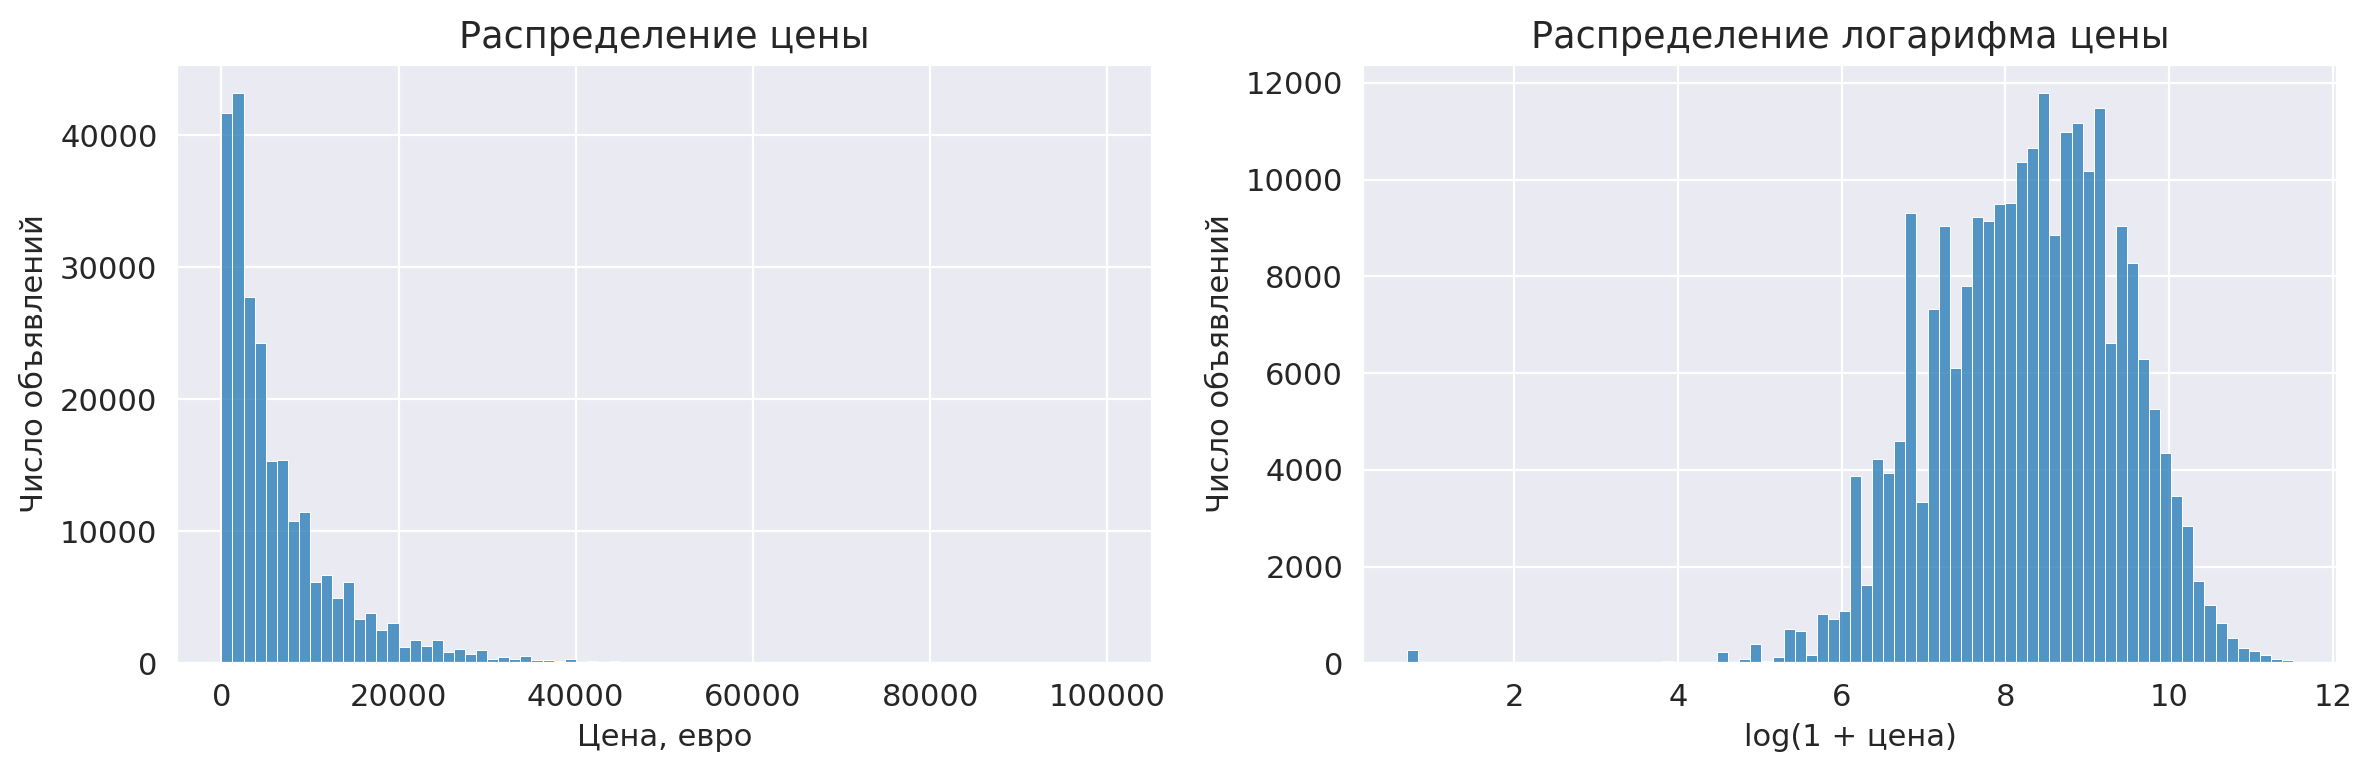

Удалено объявлений: 448
Осталось объявлений: 240742


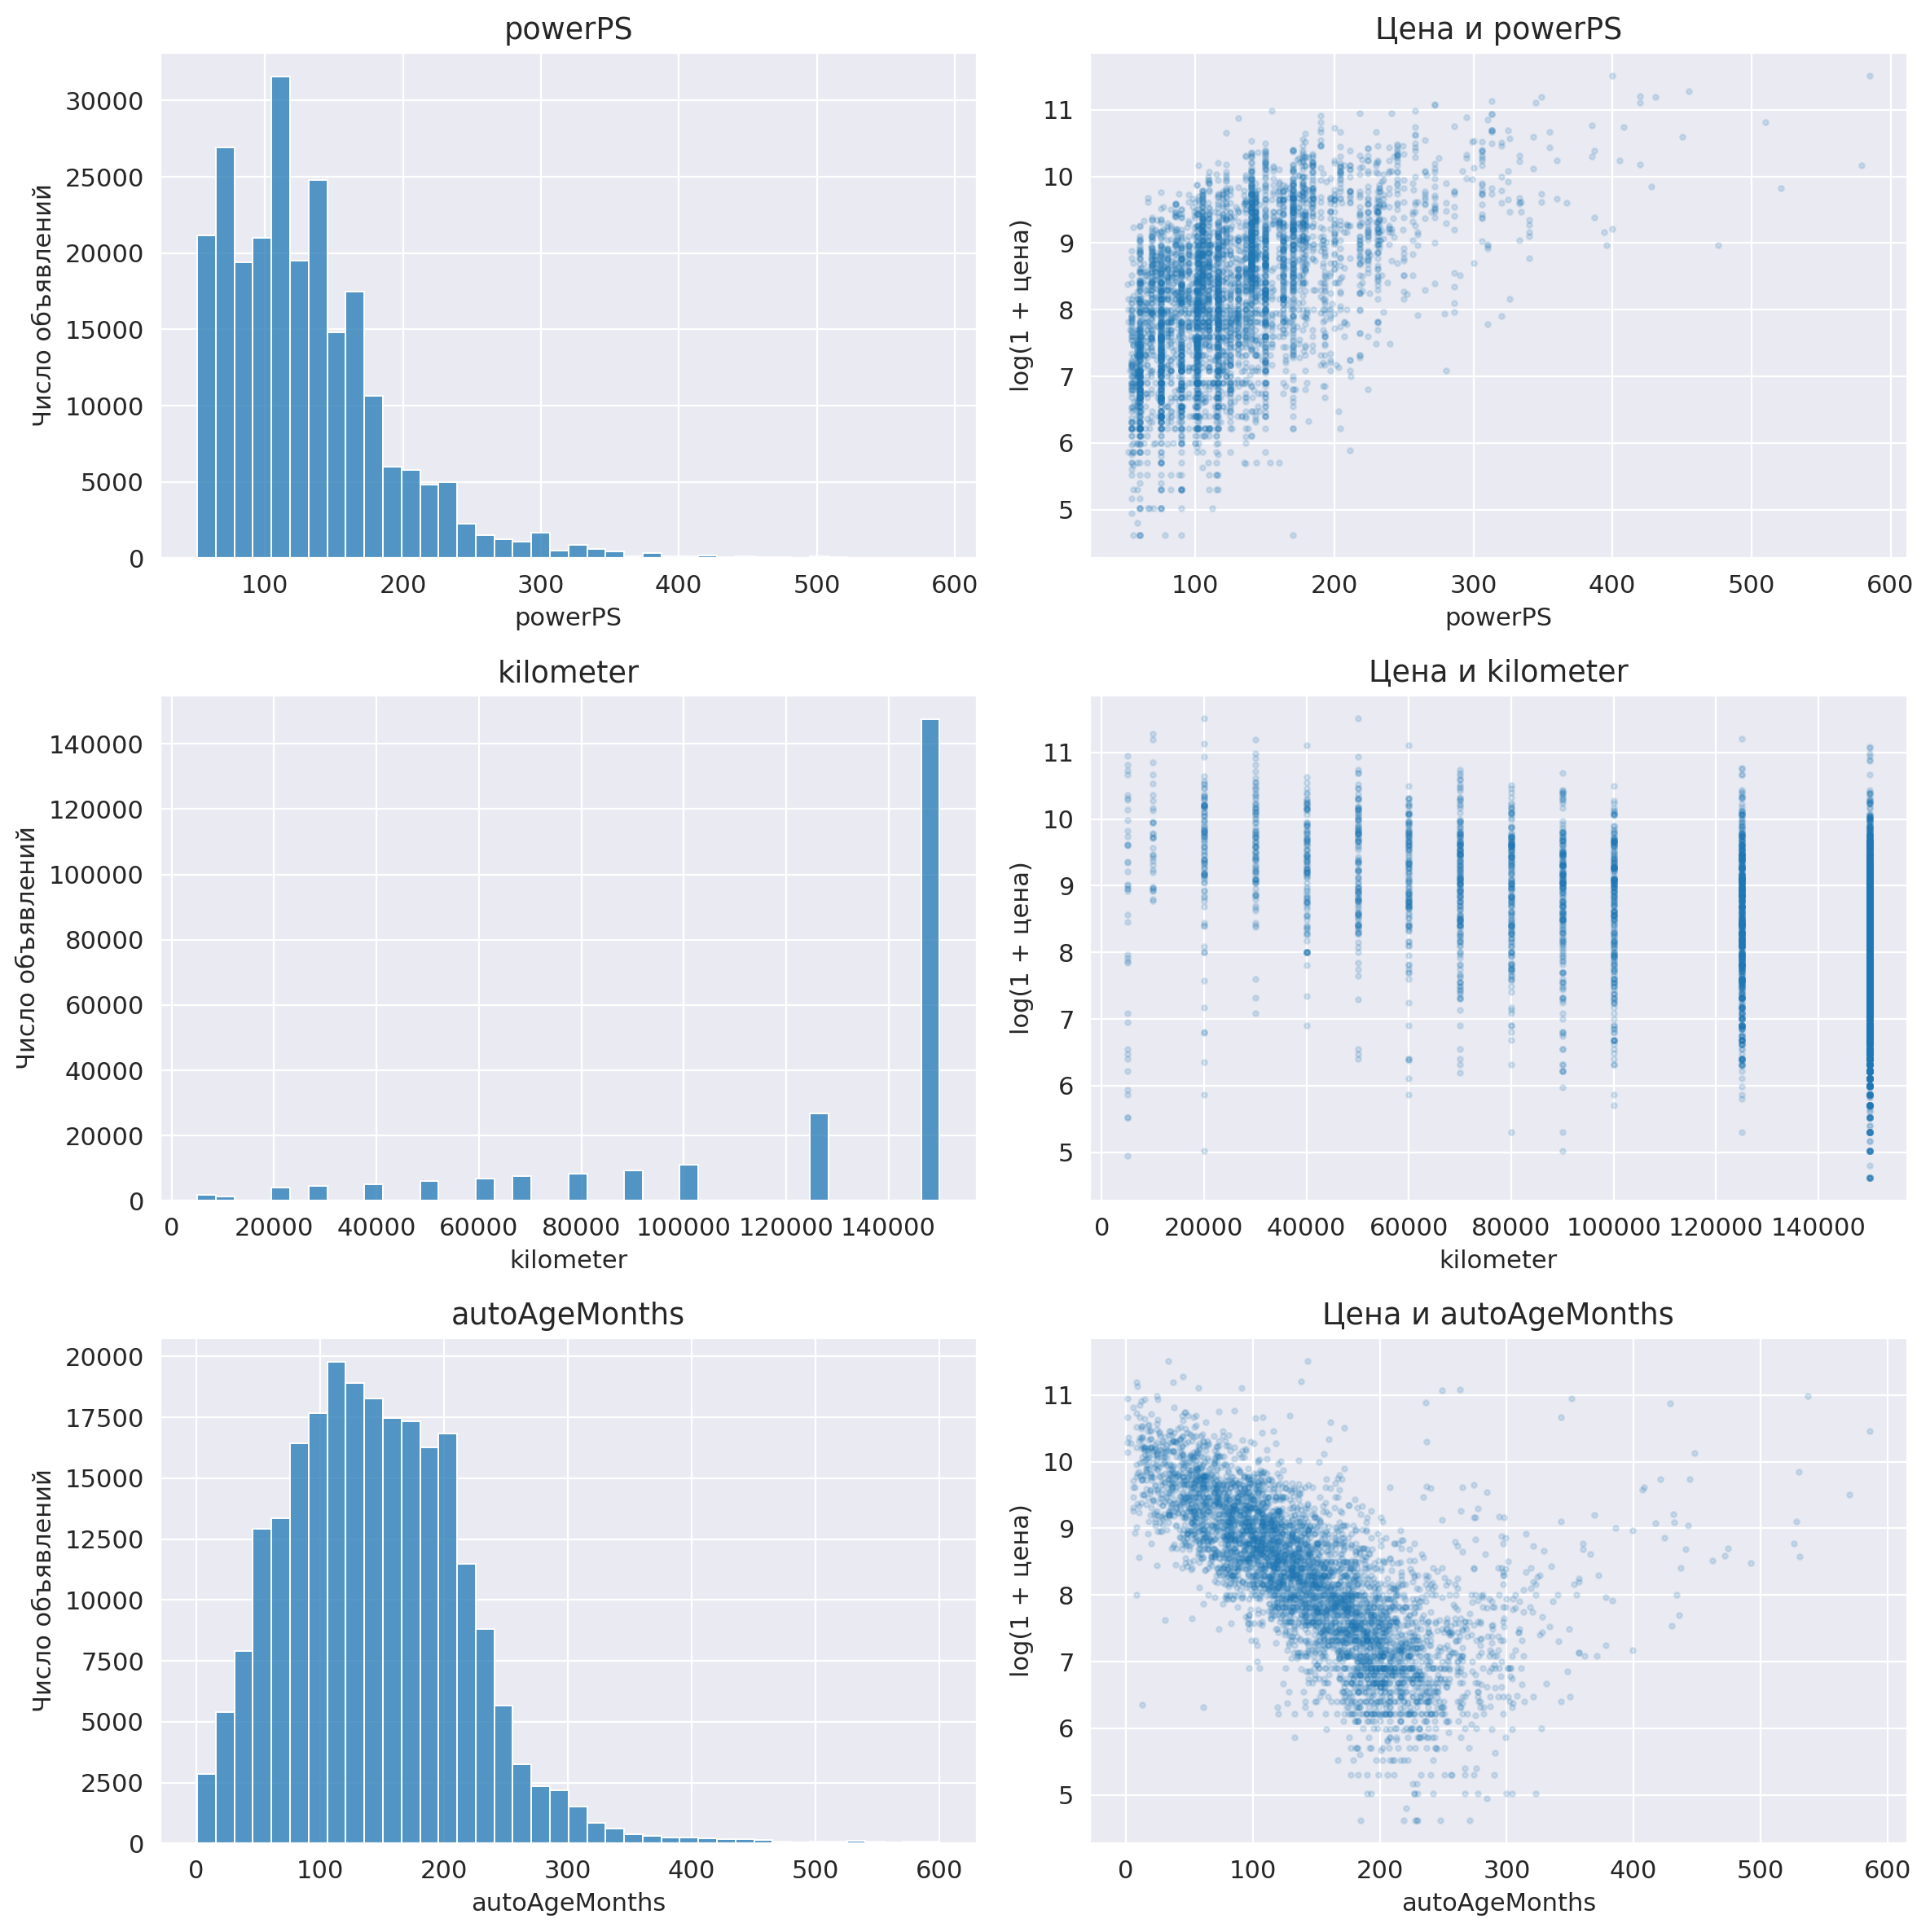

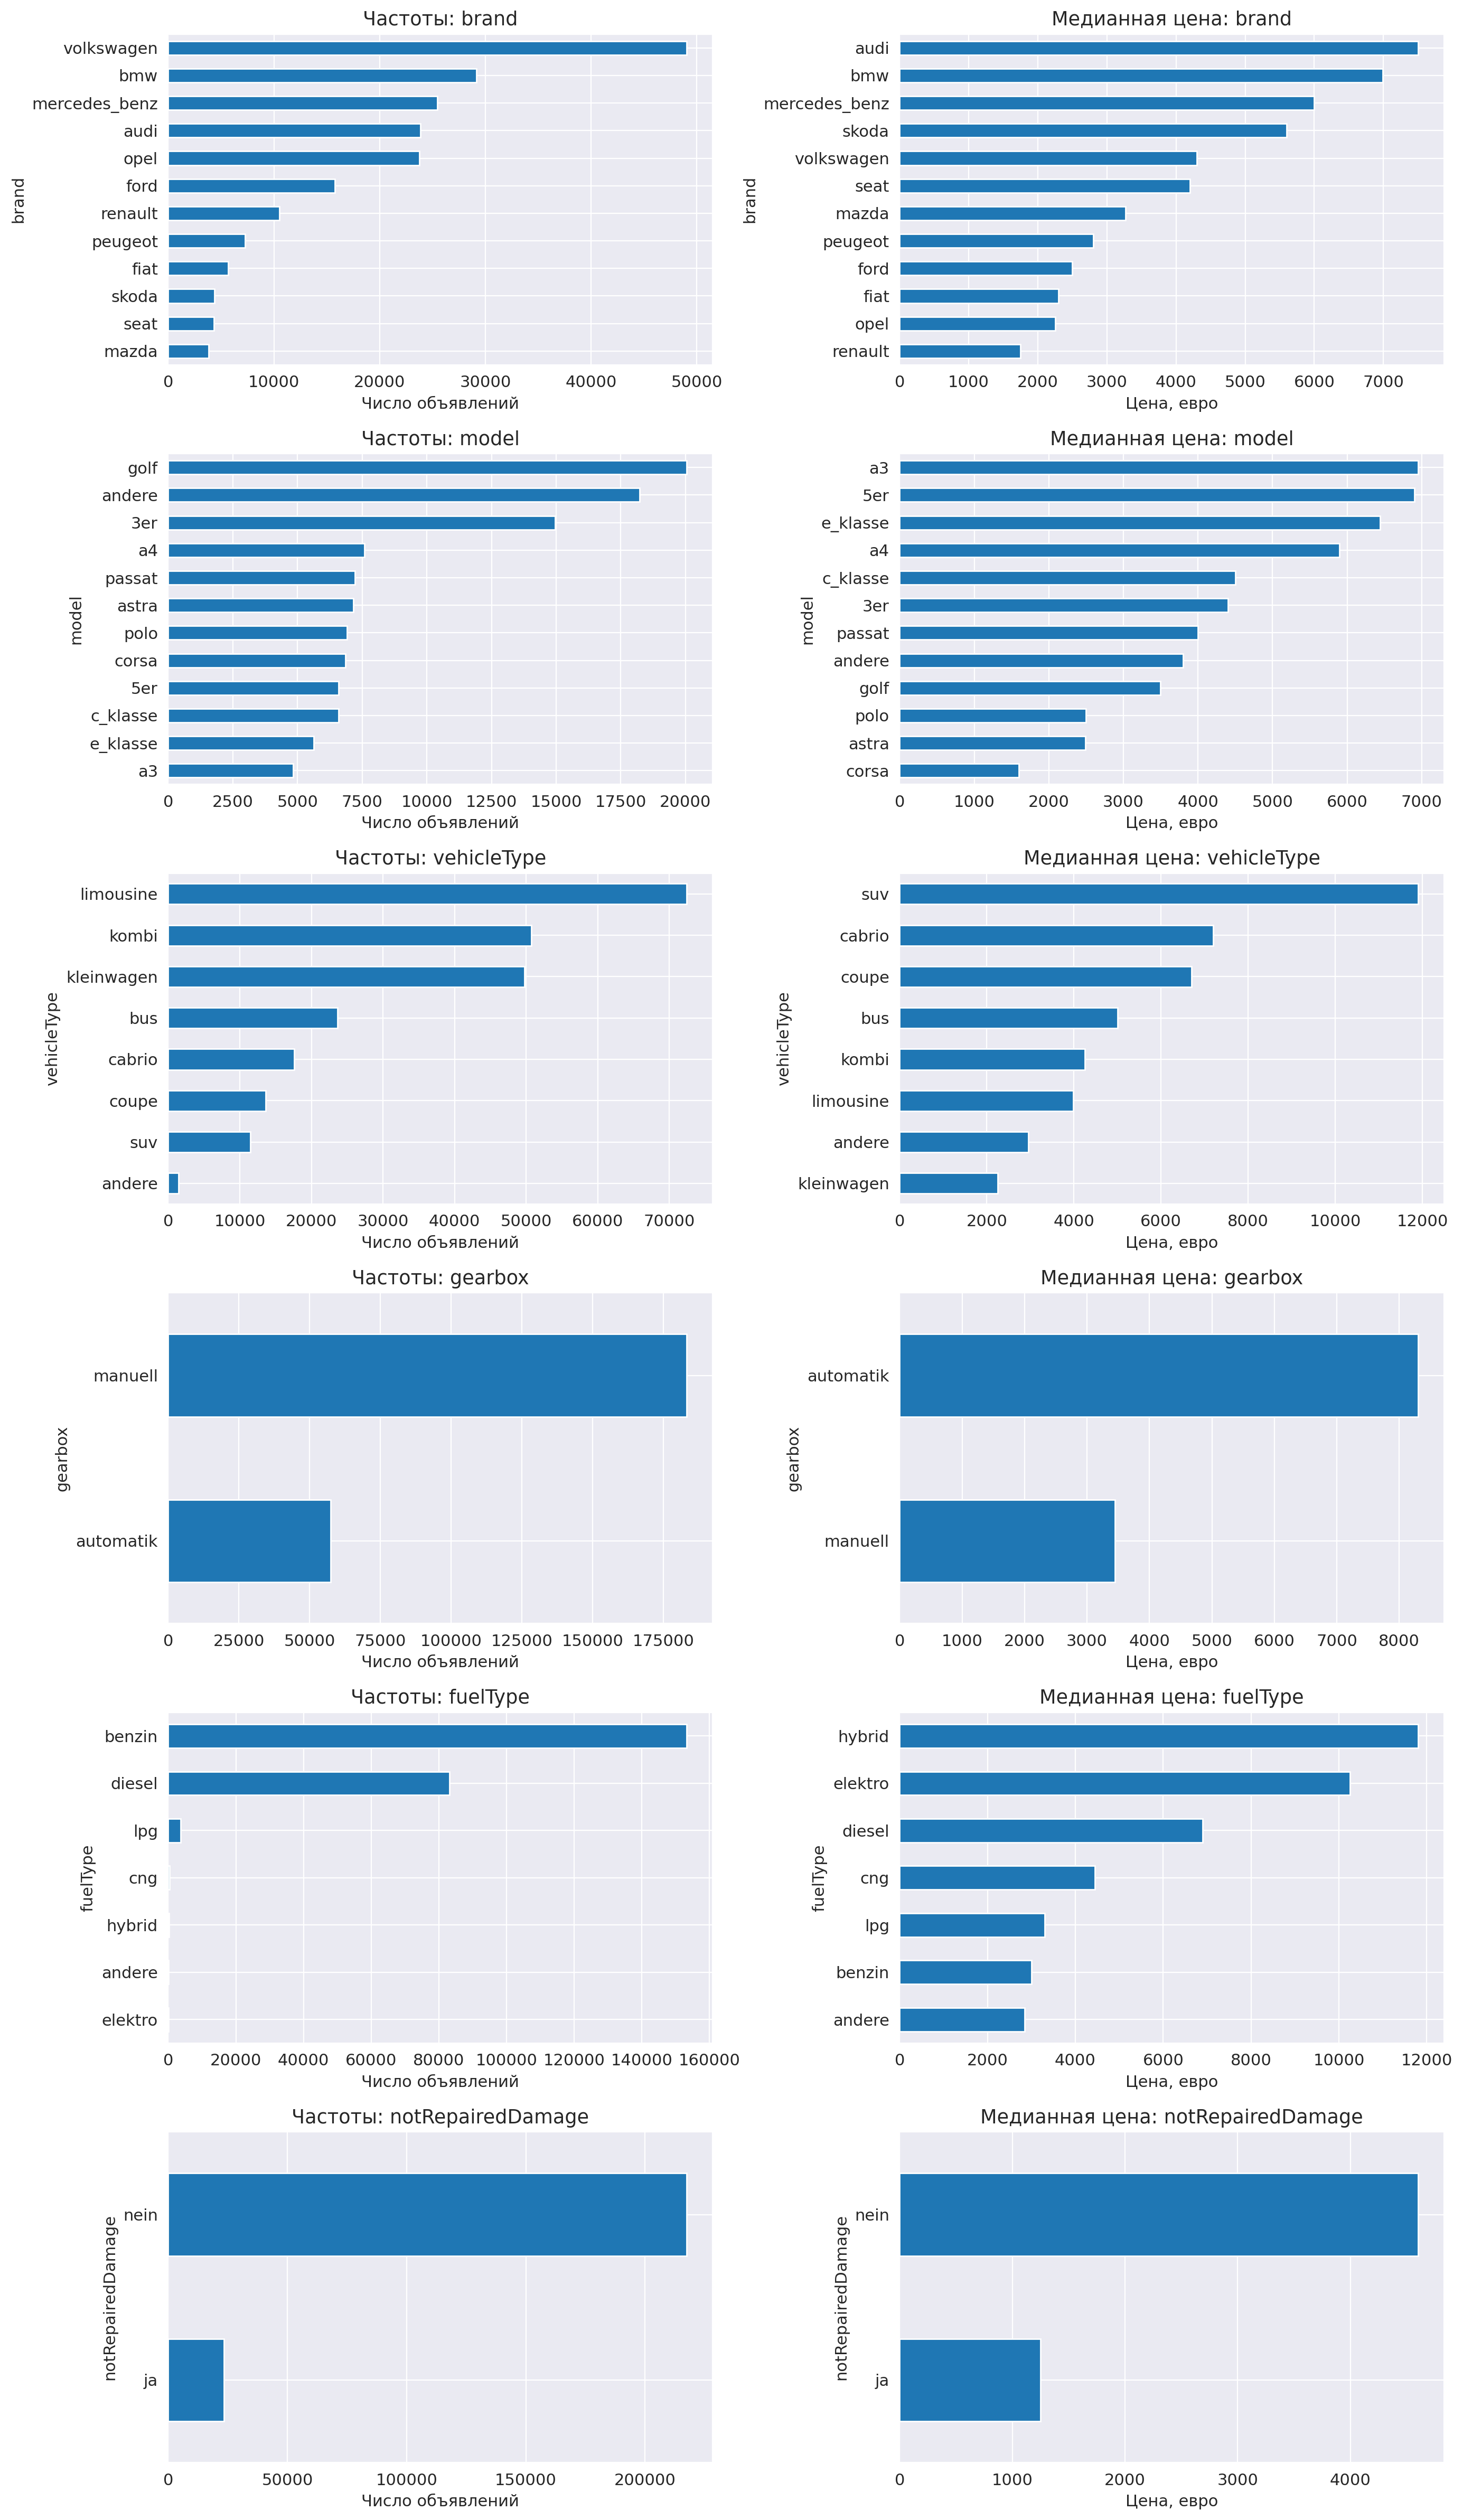

In [13]:
categorical = ['brand', 'model', 'vehicleType', 'gearbox', 'fuelType', 'notRepairedDamage']
numeric = ['powerPS', 'kilometer', 'autoAgeMonths']
other = []

display(data.dtypes.rename('Тип данных'))
display(data.describe())
print('Пропуски:', data.isna().sum().sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data['price'], bins=80, ax=axes[0])
axes[0].set(title='Распределение цены', xlabel='Цена, евро', ylabel='Число объявлений')
sns.histplot(np.log1p(data['price']), bins=80, ax=axes[1])
axes[1].set(title='Распределение логарифма цены', xlabel='log(1 + цена)', ylabel='Число объявлений')
plt.tight_layout()
plt.show()

valid_rows = (
    data['price'].between(100, 100000)
    & data['powerPS'].between(20, 1000)
    & data['kilometer'].between(1, 1000000)
    & data['autoAgeMonths'].between(1, 1200)
)
print('Удалено объявлений:', (~valid_rows).sum())
data = data[valid_rows].copy()
print('Осталось объявлений:', data.shape[0])

sample = data.sample(min(5000, data.shape[0]), random_state=42)
fig, axes = plt.subplots(3, 2, figsize=(12, 12))
for row, column in enumerate(numeric):
    sns.histplot(data[column], bins=40, ax=axes[row, 0])
    axes[row, 0].set(title=column, xlabel=column, ylabel='Число объявлений')
    axes[row, 1].scatter(sample[column], np.log1p(sample['price']), s=5, alpha=0.15)
    axes[row, 1].set(title='Цена и ' + column, xlabel=column, ylabel='log(1 + цена)')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(len(categorical), 2, figsize=(14, 24))
for row, column in enumerate(categorical):
    top_categories = data[column].value_counts().head(12)
    top_categories.sort_values().plot.barh(ax=axes[row, 0])
    axes[row, 0].set(title='Частоты: ' + column, xlabel='Число объявлений', ylabel=column)
    medians = data[data[column].isin(top_categories.index)].groupby(column)['price'].median()
    medians.sort_values().plot.barh(ax=axes[row, 1])
    axes[row, 1].set(title='Медианная цена: ' + column, xlabel='Цена, евро', ylabel=column)
plt.tight_layout()
plt.show()

Цена имеет правый хвост, поэтому используем `log(1 + price)`. Исключаем 448 объявлений дешевле 100 евро как подозрительные; высокая цена сама по себе не означает ошибку. Цена растёт с мощностью и снижается с возрастом и пробегом; категориальные признаки различают ценовые группы. Сохраняем все девять признаков: численные стандартизуем, категориальные кодируем OneHot. Метрики далее считаются в логарифмической шкале.

Добавляем в данные единичную колонку `bias`, чтобы не делать отдельные параметр $b$ для свободного члена модели.

In [14]:
data['bias'] = 1
other += ['bias']

x = data[categorical + numeric + other]
y = np.log1p(data['price'])

Теперь вам необходимо разбить данные на обучающую, тестовую и валидационную выборки.

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_rest, y_train, y_rest = train_test_split(x, y, test_size=0.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_rest, y_rest, test_size=0.5, random_state=42)

print('Train:', X_train.shape[0])
print('Validation:', X_val.shape[0])
print('Test:', X_test.shape[0])
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

y_train = y_train.to_numpy()
y_val = y_val.to_numpy()
y_test = y_test.to_numpy()

Train: 192593
Validation: 24074
Test: 24075


А также сделаем базовую обработку данных, а именно:
* Применим `OneHotEncoding` к категориальным признакам
* Стандартизуем численные признаки с помощью `StandardScaler`
* Остальные признаки трогать не будем, т.к. с ними непонятно что делать

> А почему мы сначала делим данные, а только потом применяем обработку данных? Энкодеры и скейлеры используют информацию о данных: если сделать fit на всем датасете до split, это будет утечка: статистики из val/test попадут в обучение.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from scipy import sparse

column_transformer = ColumnTransformer([
    ('ohe', OneHotEncoder(handle_unknown='ignore'), categorical),
    ('scaling', StandardScaler(), numeric),
    ('other', 'passthrough', other)
], sparse_threshold=1.0)

X_train = column_transformer.fit_transform(X_train).tocsr()
X_val = column_transformer.transform(X_val).tocsr()
X_test = column_transformer.transform(X_test).tocsr()

print('Число признаков после обработки:', X_train.shape[1])
assert np.allclose(X_train[:, -1].toarray(), 1)

Число признаков после обработки: 310


## Задание 5. Сравнение методов градиентного спуска (1.5 балла)

В этом задании вам предстоит сравнить методы градиентного спуска на подготовленных вами данных из предыдущего задания.

### Задание 5.1. Подбор оптимальной длины шага (0.75 балла)

Подберите по валидационной выборке наилучшую длину шага $\lambda$ для каждого метода с точки зрения ошибки. Для этого сделайте перебор по логарифмической сетке. Для каждого метода посчитайте ошибку на обучающей и тестовой выборках, посчитайте качество по метрике $R^2$, сохраните количество итераций до сходимости.

Все параметры кроме `lambda_` стоит выставить равным значениям по умолчанию.

In [17]:
from time import perf_counter
import gc
from sklearn.metrics import mean_squared_error, r2_score

optimizer_classes = {
    'Vanilla': VanillaGradientDescent,
    'SGD': StochasticGradientDescent,
    'SAG': SAGDescent,
    'Momentum': MomentumDescent,
    'Adam': Adam
}
lambda_grid = np.logspace(-3, 1, 5)


def fit_model(optimizer_class, lambda_, loss_function=None, seed=42, **optimizer_params):
    gc.collect()
    np.random.seed(seed)
    optimizer = optimizer_class(lr_schedule=TimeDecayLR(lambda_=lambda_), **optimizer_params)
    model = CustomLinearRegression(optimizer, loss_function=loss_function)
    start = perf_counter()
    model.fit(X_train, y_train)
    elapsed = perf_counter() - start
    if isinstance(optimizer, SAGDescent):
        optimizer.grad_memory = None
    return model, elapsed


def validation_mse(model):
    if not np.isfinite(model.w).all() or model.optimizer.stop_reason == 'nonfinite':
        return np.inf
    with np.errstate(over='ignore', invalid='ignore'):
        predictions = model.predict(X_val)
        value = np.mean((predictions - y_val) ** 2)
    return float(value) if np.isfinite(value) else np.inf


def model_metrics(model, method, lambda_, elapsed):
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    return {
        'method': method,
        'lambda': lambda_,
        'train_mse': mean_squared_error(y_train, train_pred),
        'val_mse': validation_mse(model),
        'test_mse': mean_squared_error(y_test, test_pred),
        'train_r2': r2_score(y_train, train_pred),
        'test_r2': r2_score(y_test, test_pred),
        'iterations': model.optimizer.iteration,
        'stop_reason': model.optimizer.stop_reason,
        'seconds': elapsed
    }


best_models = {}
best_lambdas = {}
baseline_rows = []
lambda_search_rows = []

for method, optimizer_class in optimizer_classes.items():
    best_model = None
    best_score = np.inf
    for lambda_ in lambda_grid:
        model, elapsed = fit_model(optimizer_class, lambda_)
        score = validation_mse(model)
        lambda_search_rows.append({'method': method, 'lambda': lambda_, 'val_mse': score})
        if score < best_score:
            best_score = score
            best_model = model
            best_lambda = lambda_
            best_elapsed = elapsed
    if best_model is None:
        raise ValueError('Не найден устойчивый шаг для ' + method)
    best_models[method] = best_model
    best_lambdas[method] = best_lambda
    baseline_rows.append(model_metrics(best_model, method, best_lambda, best_elapsed))
    print(method, 'лучший шаг:', best_lambda, 'validation MSE:', round(best_score, 4))

lambda_search = pd.DataFrame(lambda_search_rows)
baseline_results = pd.DataFrame(baseline_rows).set_index('method')
display(baseline_results)
print('MSE и R² рассчитаны для log(1 + цена).')

Vanilla лучший шаг: 1.0 validation MSE: 0.2957


SGD лучший шаг: 0.1 validation MSE: 0.3614


SAG лучший шаг: 1.0 validation MSE: 1.5411


Momentum лучший шаг: 1.0 validation MSE: 0.2732


Adam лучший шаг: 10.0 validation MSE: 0.2692


,lambda,train_mse,val_mse,test_mse,train_r2,test_r2,iterations,stop_reason,seconds
method,,,,,,,,,
Vanilla,1.0,0.295300,0.295655,0.295220,0.763968,0.762310,394,tolerance,3.250091
SGD,0.1,0.359815,0.361362,0.359498,0.712402,0.710558,792,tolerance,2.577346
SAG,1.0,1.552019,1.541129,1.549302,-0.240520,-0.247388,1000,max_iter,3.840730
Momentum,1.0,0.271493,0.273150,0.271067,0.782997,0.781756,802,tolerance,6.559960
Adam,10.0,0.266414,0.269228,0.265360,0.787057,0.786351,1000,max_iter,8.764111


MSE и R² рассчитаны для log(1 + цена).


### Задание 5.2. Сравнение методов (0.75 балла)

Постройте график зависимости ошибки на обучающей выборке от номера итерации (все методы на одном графике).

Посмотрите на получившиеся результаты (таблички с метриками и график). Сравните методы между собой.

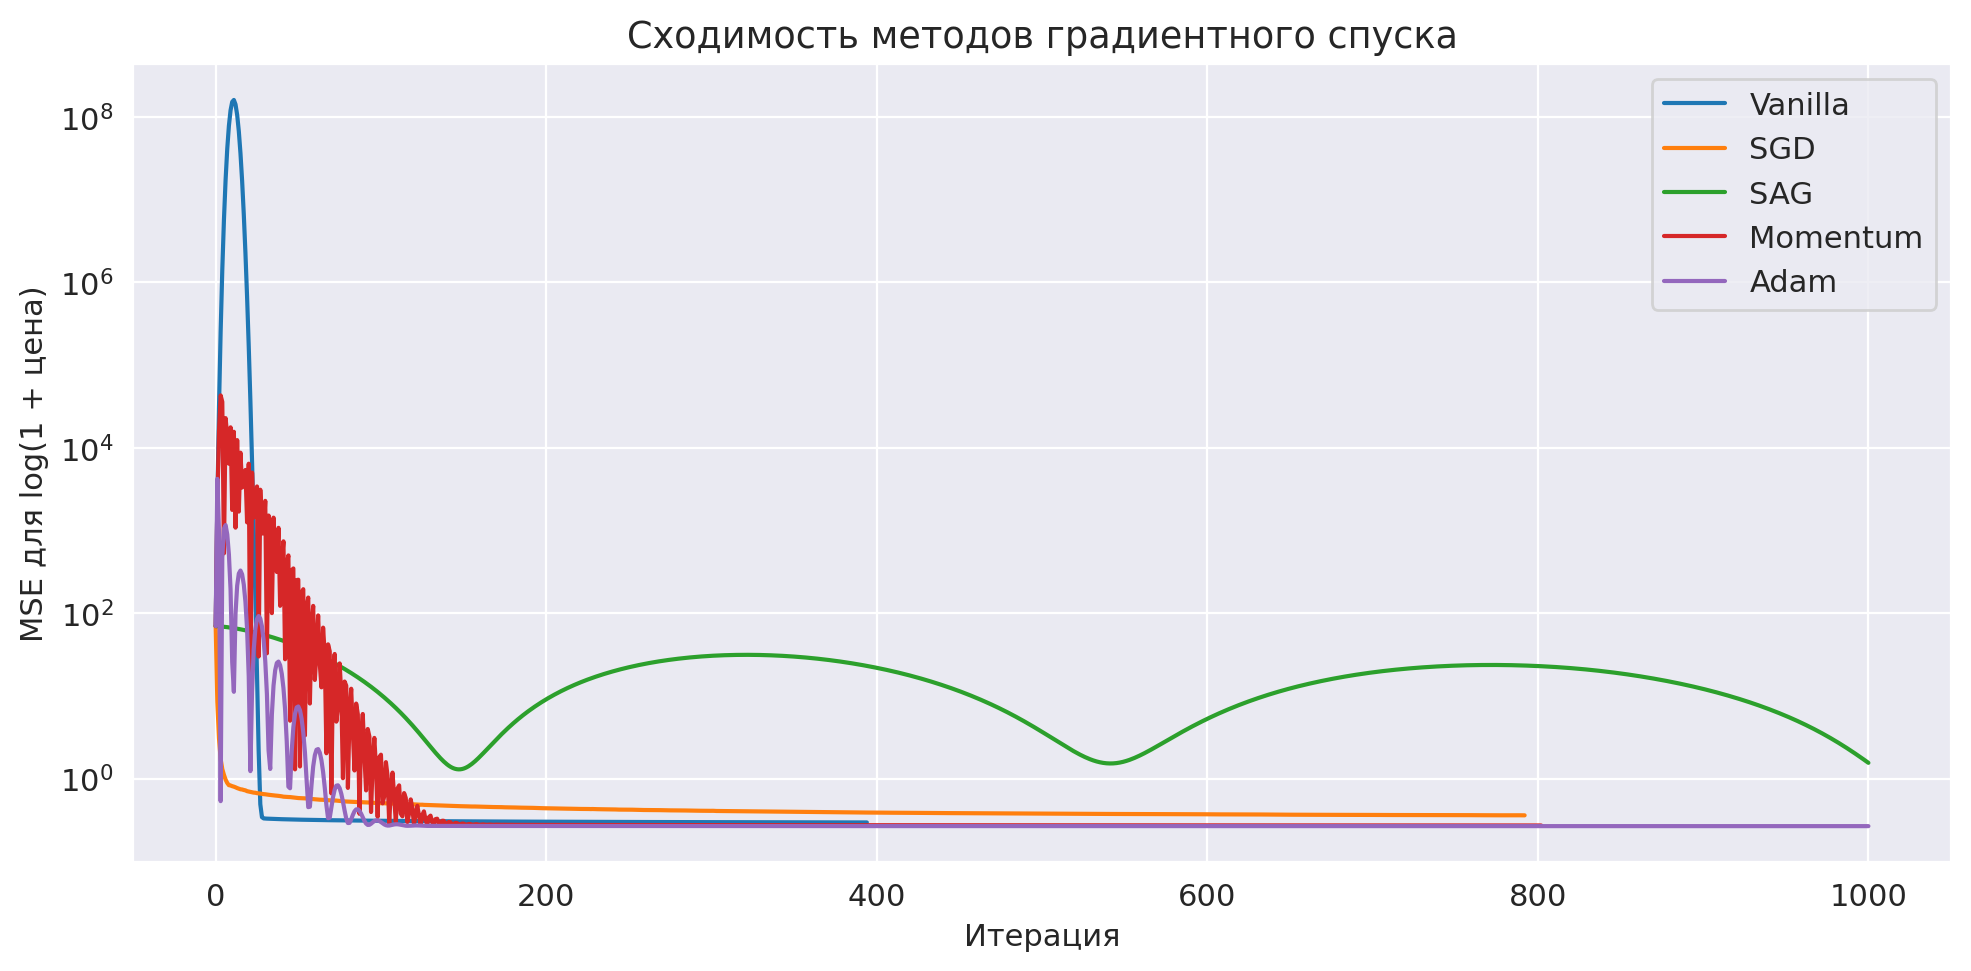

Лучший метод по validation MSE: Adam
Самое быстрое обучение выбранной модели: SGD
Остановились по tolerance:
Vanilla, SGD, Momentum


In [18]:
fig, ax = plt.subplots(figsize=(10, 5))
for method, model in best_models.items():
    ax.plot(model.loss_history, label=method)
ax.set(xlabel='Итерация', ylabel='MSE для log(1 + цена)', title='Сходимость методов градиентного спуска')
ax.set_yscale('log')
ax.legend()
plt.tight_layout()
plt.show()

print('Лучший метод по validation MSE:', baseline_results['val_mse'].idxmin())
print('Самое быстрое обучение выбранной модели:', baseline_results['seconds'].idxmin())
print('Остановились по tolerance:')
print(', '.join(baseline_results.index[baseline_results['stop_reason'] == 'tolerance']) or 'Ни один метод')

Лучший validation MSE у Adam (0.269), быстрее всего в этом запуске обучился выбранный SGD. Vanilla и Momentum сначала сильно колеблются. SAG при батче 32 показал слабое качество; SAG и Adam остановились по лимиту 1000 итераций. Время включает расчёт полного loss на каждом шаге.

## Задание 6. Стохастический градиентный спуск и размер батча (1 балл)

В этом задании вам предстоит исследовать влияние размера батча на работу стохастического градиентного спуска.

* Сделайте по несколько запусков (например, $k = 10$) стохастического градиентного спуска на обучающей выборке для каждого размера батча из перебираемого списка. Замерьте время в секундах и количество итераций до сходимости. Посчитайте среднее этих значений для каждого размера батча.
* Постройте график зависимости количества шагов до сходимости от размера батча. _(под сходимостью понимается достижение критерия останова)_
* Постройте график зависимости времени до сходимости от размера батча.

Посмотрите на получившиеся результаты. Какие выводы можно сделать про подбор размера батча для стохастического градиентного спуска?

Размер батча: 1 запусков: 10


Размер батча: 8 запусков: 10


Размер батча: 32 запусков: 10


Размер батча: 128 запусков: 10


Размер батча: 512 запусков: 10


Размер батча: 2048 запусков: 10


,iterations_mean,iterations_std,seconds_mean,seconds_std,tolerance_fraction,val_mse
batch_size,,,,,,
1,111.3,49.616418,0.327568,0.139485,1.0,1.314790
8,799.9,191.560521,2.376992,0.605302,0.6,0.380837
32,831.2,150.457672,2.559772,0.443651,0.7,0.367161
128,527.0,54.174615,1.458293,0.181239,1.0,0.386709
512,381.7,33.266767,1.129021,0.115882,1.0,0.404741
2048,350.6,12.194717,1.286625,0.140481,1.0,0.410456


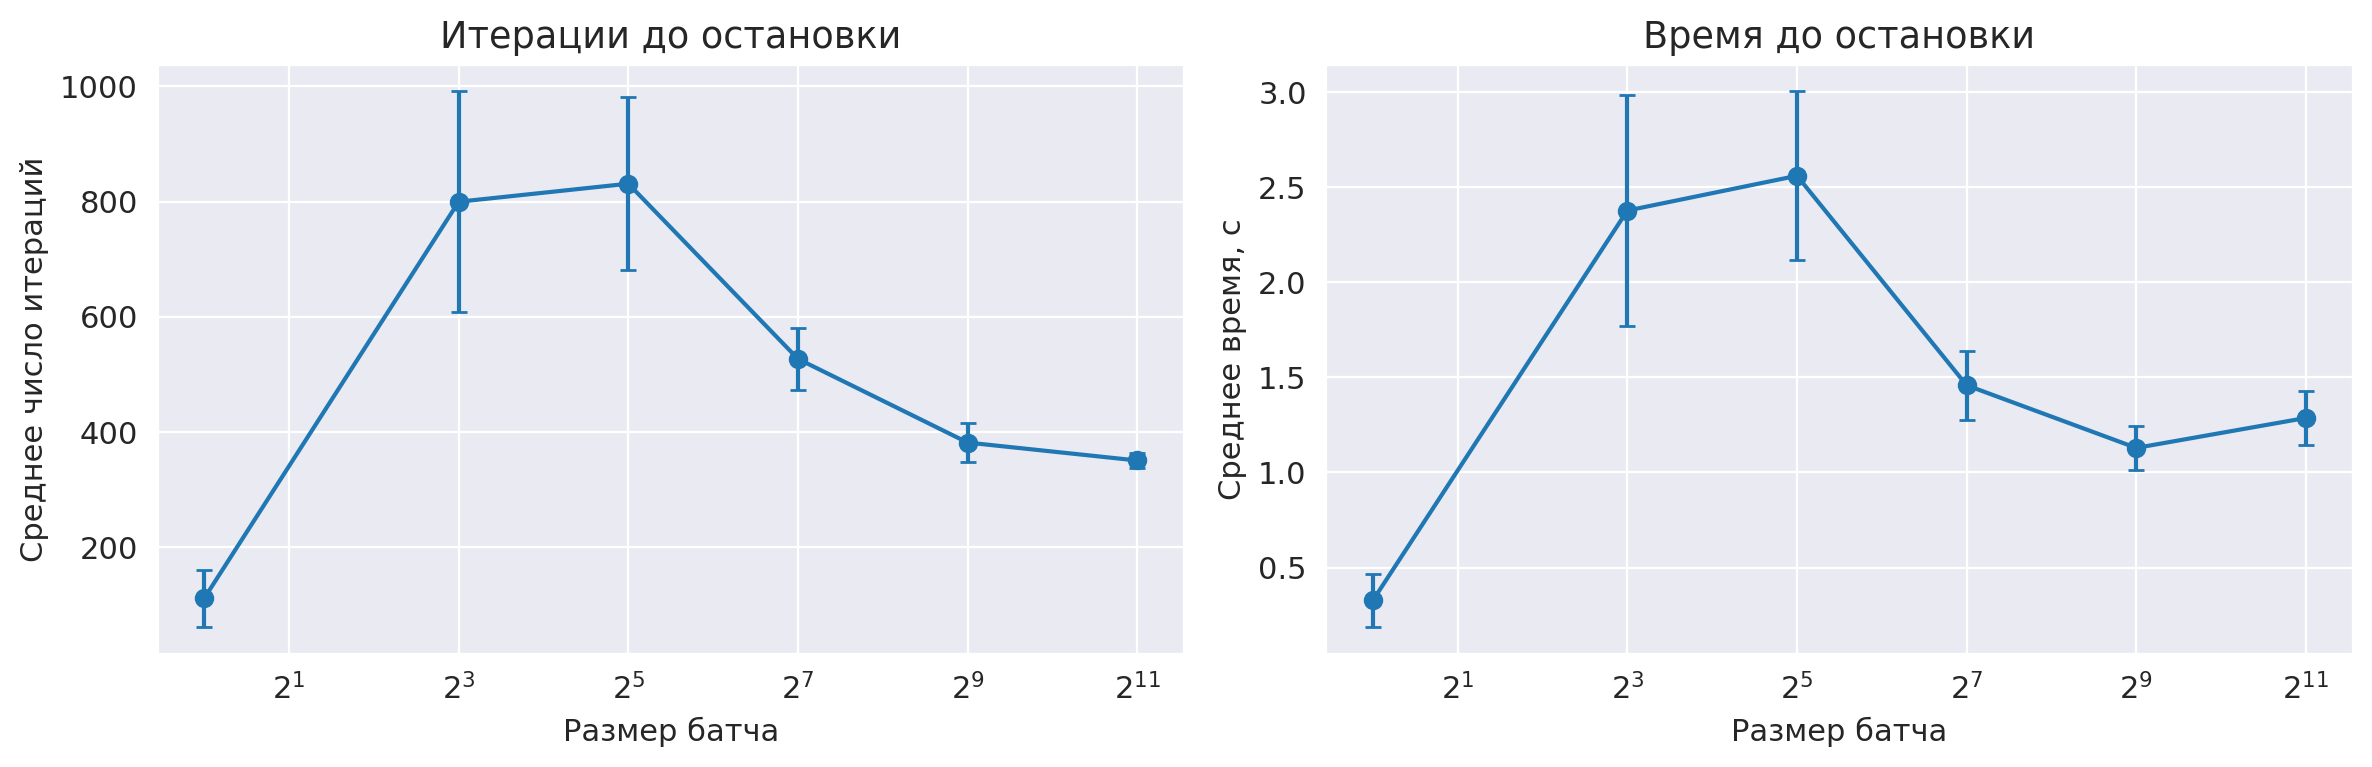

In [19]:
batch_sizes = [1, 8, 32, 128, 512, 2048]
k = 10
batch_rows = []

for batch_size in batch_sizes:
    for seed in range(k):
        model, elapsed = fit_model(
            StochasticGradientDescent,
            best_lambdas['SGD'],
            seed=seed,
            batch_size=batch_size
        )
        batch_rows.append({
            'batch_size': batch_size,
            'seed': seed,
            'iterations': model.optimizer.iteration,
            'seconds': elapsed,
            'tolerance_reached': model.optimizer.stop_reason == 'tolerance',
            'val_mse': validation_mse(model)
        })
    print('Размер батча:', batch_size, 'запусков:', k)

batch_runs = pd.DataFrame(batch_rows)
batch_results = batch_runs.groupby('batch_size').agg(
    iterations_mean=('iterations', 'mean'),
    iterations_std=('iterations', 'std'),
    seconds_mean=('seconds', 'mean'),
    seconds_std=('seconds', 'std'),
    tolerance_fraction=('tolerance_reached', 'mean'),
    val_mse=('val_mse', 'mean')
)
display(batch_results)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].errorbar(batch_results.index, batch_results['iterations_mean'],
                 yerr=batch_results['iterations_std'], marker='o', capsize=3)
axes[0].set(xlabel='Размер батча', ylabel='Среднее число итераций', title='Итерации до остановки')
axes[1].errorbar(batch_results.index, batch_results['seconds_mean'],
                 yerr=batch_results['seconds_std'], marker='o', capsize=3)
axes[1].set(xlabel='Размер батча', ylabel='Среднее время, с', title='Время до остановки')
axes[0].set_xscale('log', base=2)
axes[1].set_xscale('log', base=2)
plt.tight_layout()
plt.show()

**Выводы:** При фиксированном шаге батч 1 быстро останавливается, но даёт худший MSE: критерий срабатывает слишком рано. Лучший средний validation MSE получен при батче 32. Батчи 512 и 2048 останавливаются быстрее, но качество хуже; батч 2048 уже не даёт выигрыша по времени относительно 512.

## Задание 7. Регуляризация (0.5 балла)

В этом задании вам предстоит исследовать влияние регуляризации на работу различных методов градиентного спуска. Напомним, регуляризация – это добавка к функции потерь, которая штрафует за норму весов. Мы будем использовать $L_2$-регуляризацию, таким образом функция потерь приобретает следующий вид:

$$
    Q(w) = \dfrac{1}{\ell} \sum\limits_{i=1}^{\ell} (a_w(x_i) - y_i)^2 + \dfrac{\mu}{2} \| w \|^2
$$

Допишите класс `linear_regression.L2Regularization`, следуя интерфейсу и докуметации.

Используя регуляризованный лосс в эксприментах, найдите лучшие параметры обучения с регуляризацией аналогично 5 заданию. Будем подбирать длину шага $\lambda$ (`lambda_`) и коэффициент регуляризации $\mu$ (`mu`).

Сравните для каждого метода результаты с регуляризацией и без регуляризации (нужно опять сохранить ошибку и качество по метрике $R^2$ на обучающей и тестовой выборках и количество итераций до сходимости).

Постройте для каждого метода график со значениями функции потерь MSE с регуляризацией и без регуляризации (всего должно получиться 5 графиков).

Посмотрите на получившиеся результаты. Какие можно сделать выводы, как регуляризация влияет на сходимость? Как изменилось качество на обучающей выборке? На тестовой? Чем вы можете объяснить это?

Vanilla lambda: 1.0 mu: 0.0001


SGD lambda: 0.1 mu: 0.0001


SAG lambda: 1.0 mu: 0.1


Momentum lambda: 1.0 mu: 0.0001


Adam lambda: 10.0 mu: 0.0001


lambda  train_mse   val_mse  test_mse  train_r2  \
Регуляризация method                                                      
Без L2        Vanilla      1.0   0.295300  0.295655  0.295220  0.763968   
              SGD          0.1   0.359815  0.361362  0.359498  0.712402   
              SAG          1.0   1.552019  1.541129  1.549302 -0.240520   
              Momentum     1.0   0.271493  0.273150  0.271067  0.782997   
              Adam        10.0   0.266414  0.269228  0.265360  0.787057   
С L2          Vanilla      1.0   0.295381  0.295734  0.295298  0.763903   
              SGD          0.1   0.359849  0.361396  0.359533  0.712374   
              SAG          1.0   1.304818  1.298981  1.299873 -0.042933   
              Momentum     1.0   0.271795  0.273428  0.271402  0.782756   
              Adam        10.0   0.267401  0.269741  0.266124  0.786268   

                         test_r2  iterations stop_reason   seconds      mu  
Регуляризация method                                                        
Без L2        Vanilla   0.762310         394   tolerance  3.250091     NaN  
              SGD       0.710558         792   tolerance  2.577346     NaN  
              SAG      -0.247388        1000    max_iter  3.840730     NaN  
              Momentum  0.781756         802   tolerance  6.559960     NaN  
              Adam      0.786351        1000    max_iter  8.764111     NaN  
С L2          Vanilla   0.762247         392   tolerance  3.043742  0.0001  
              SGD       0.710530         792   tolerance  2.073328  0.0001  
              SAG      -0.046565        1000    max_iter  3.273570  0.1000  
              Momentum  0.781486         757   tolerance  5.775080  0.0001  
              Adam      0.785736        1000    max_iter  9.253670  0.0001

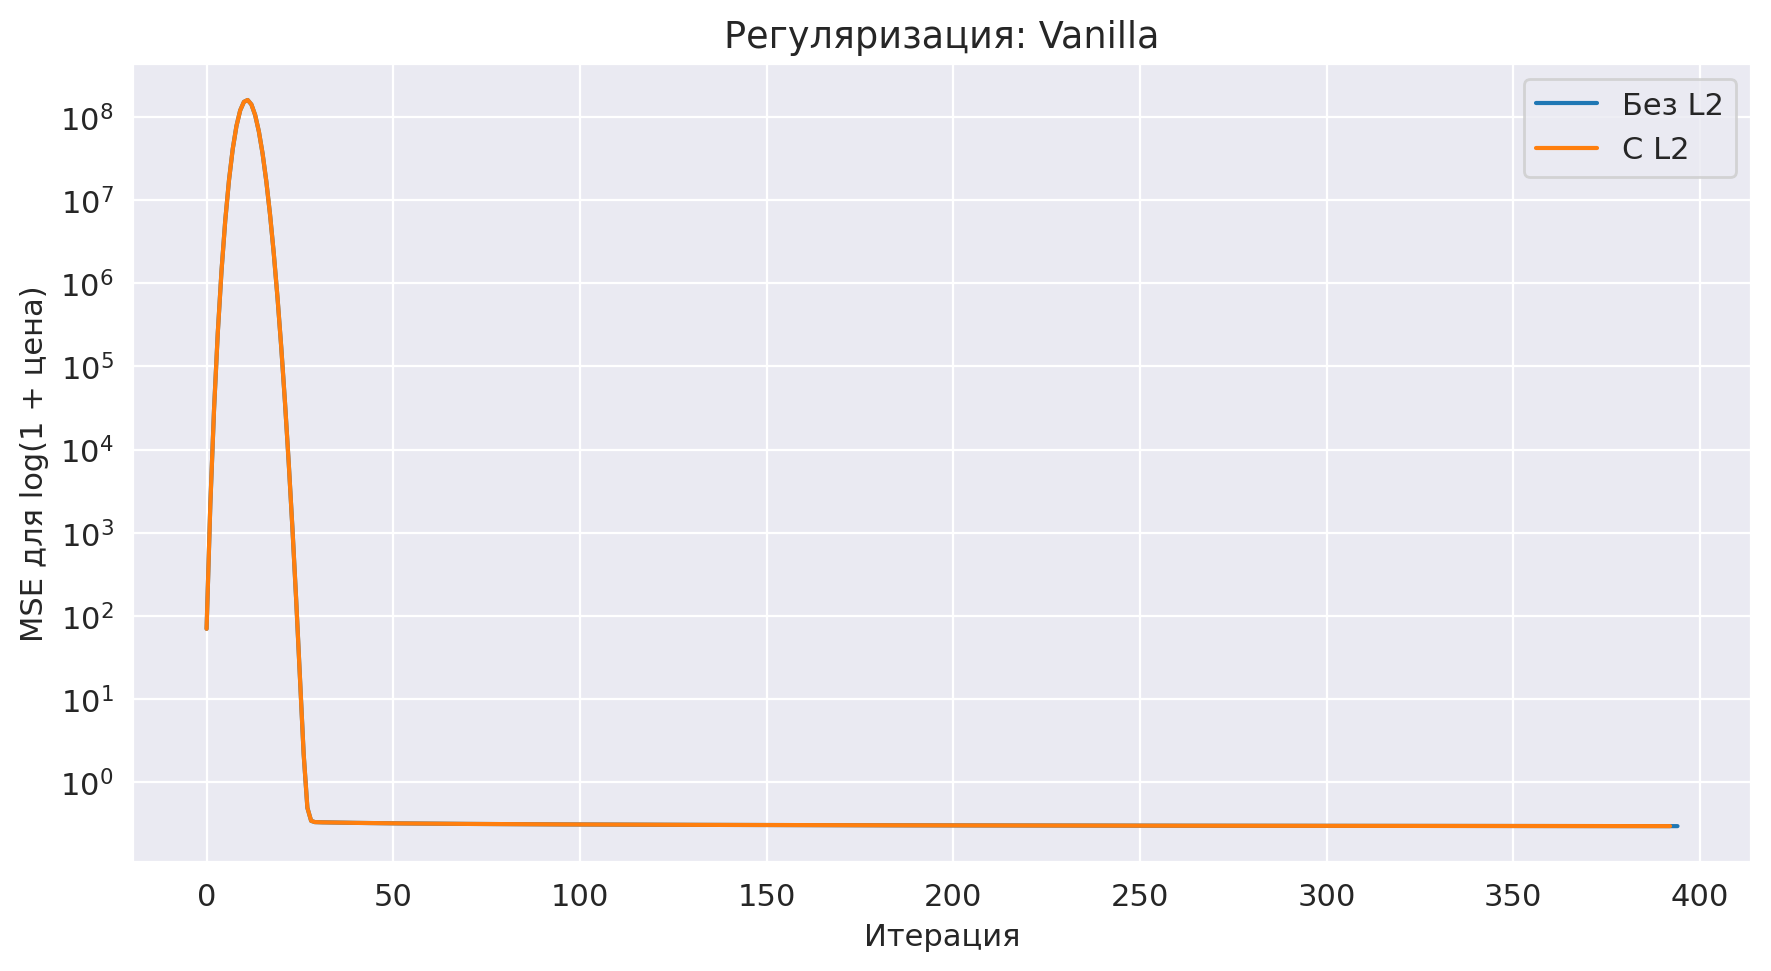

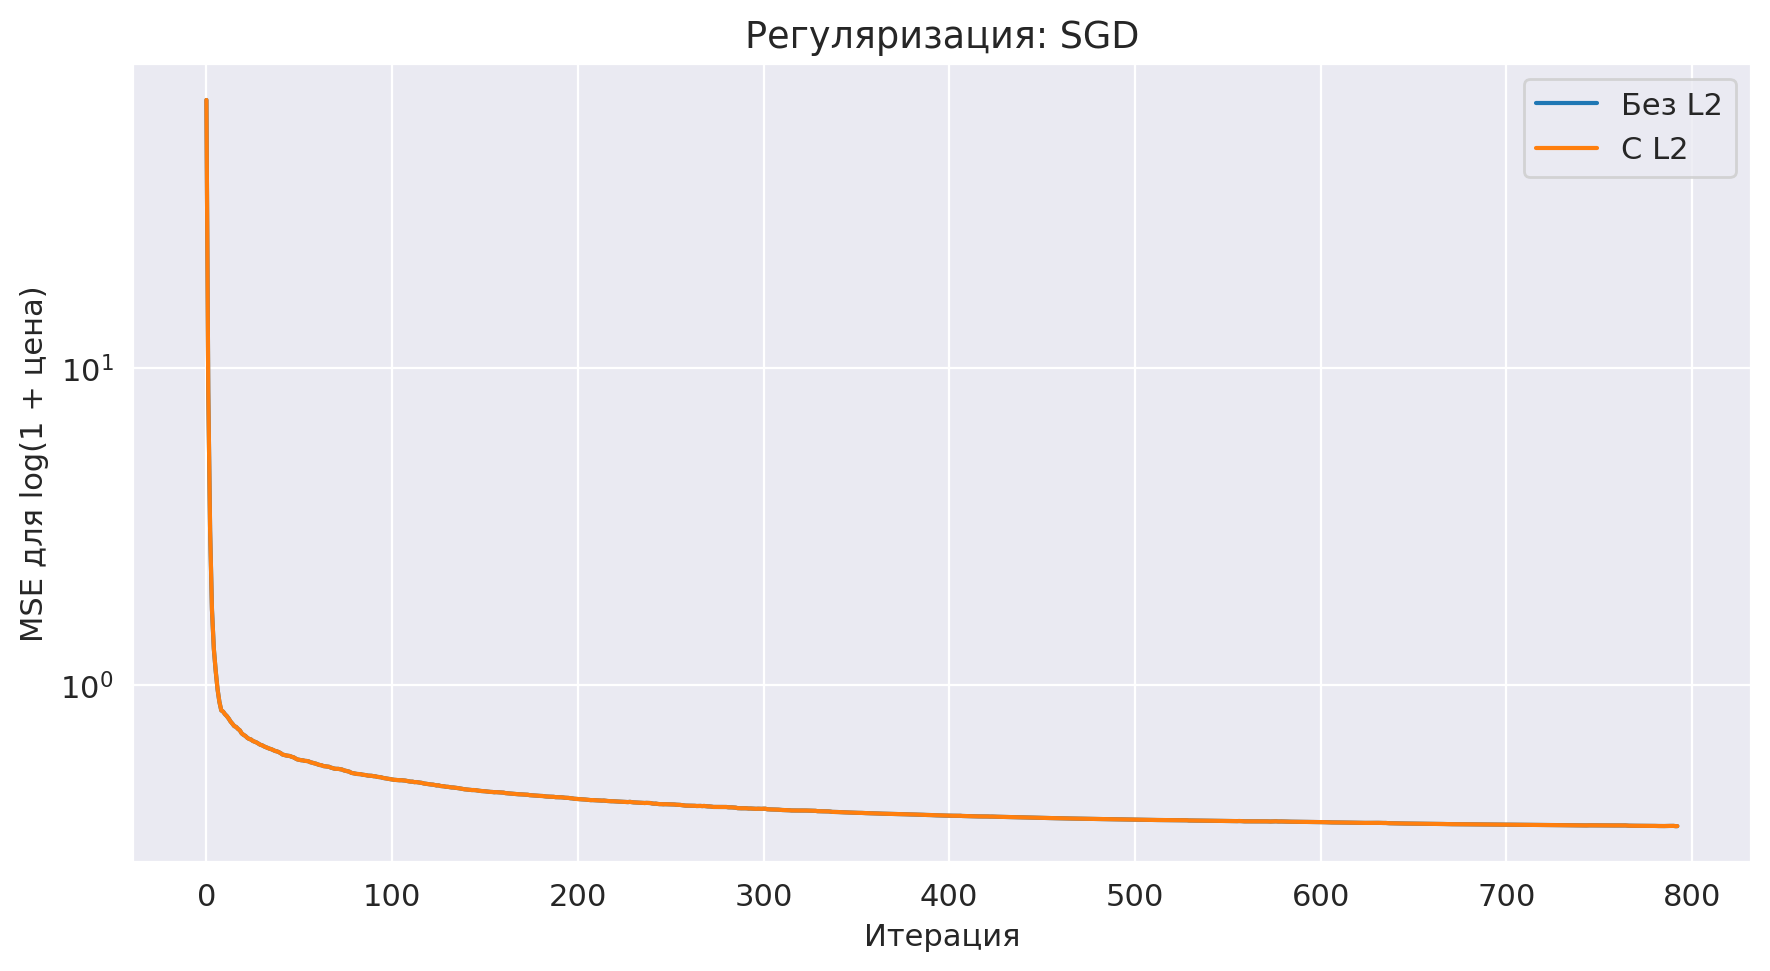

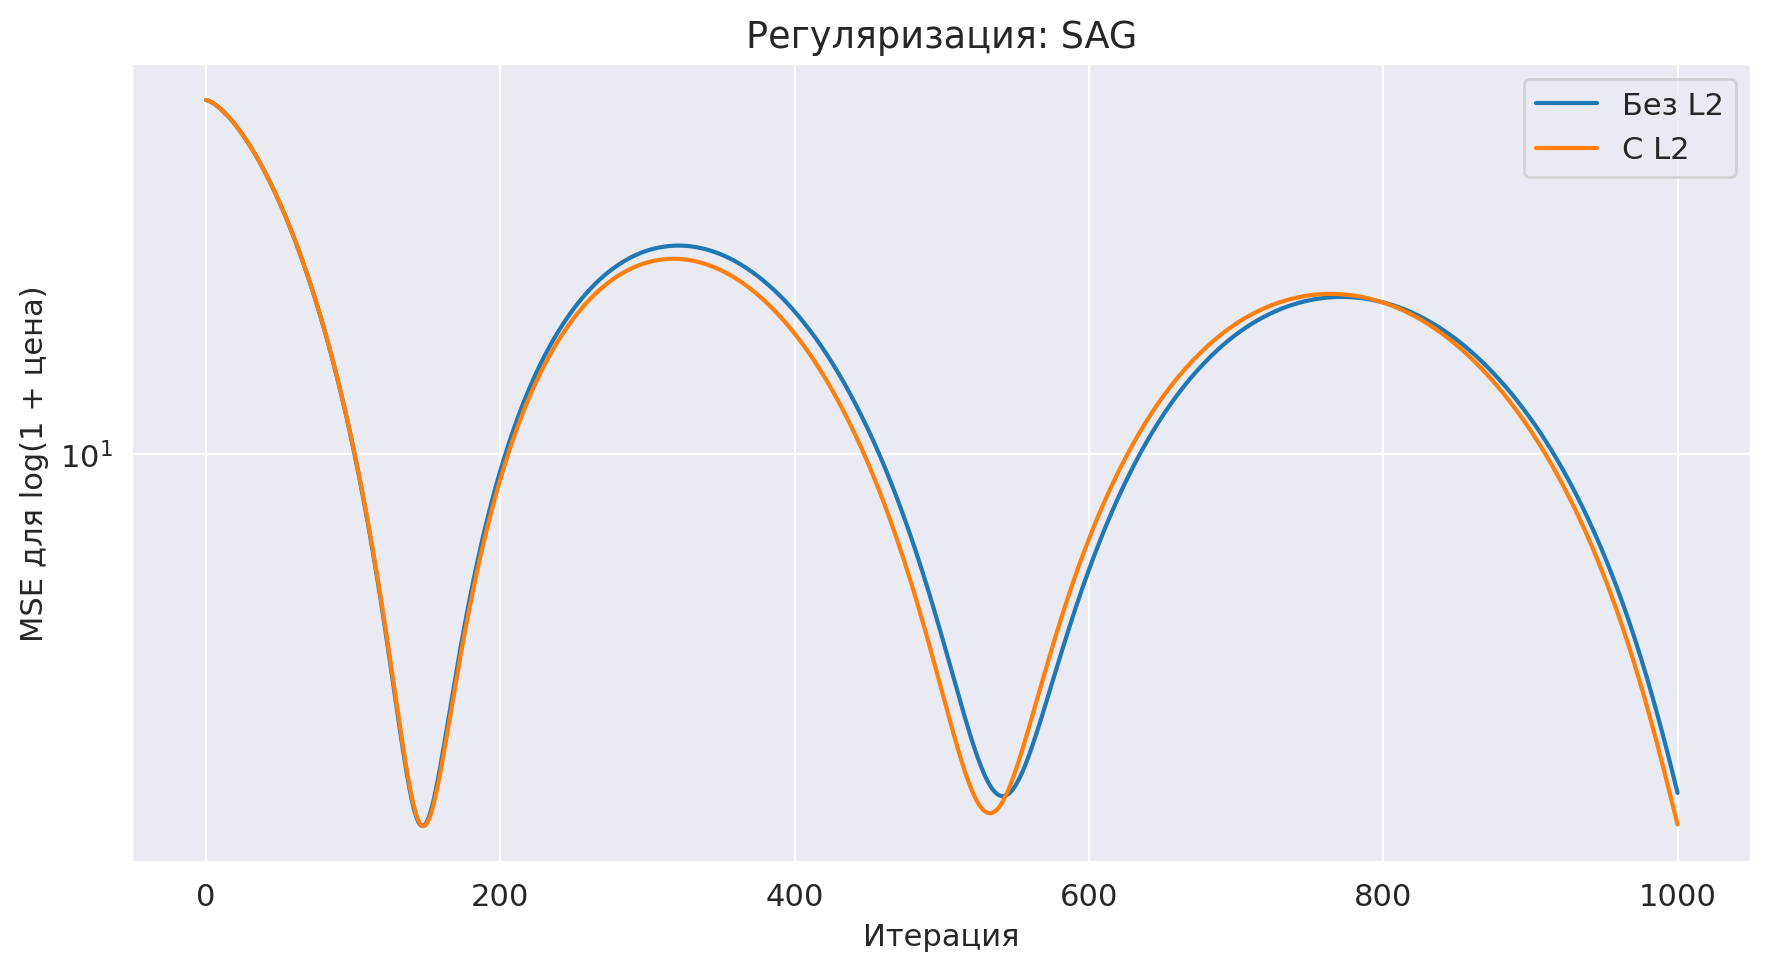

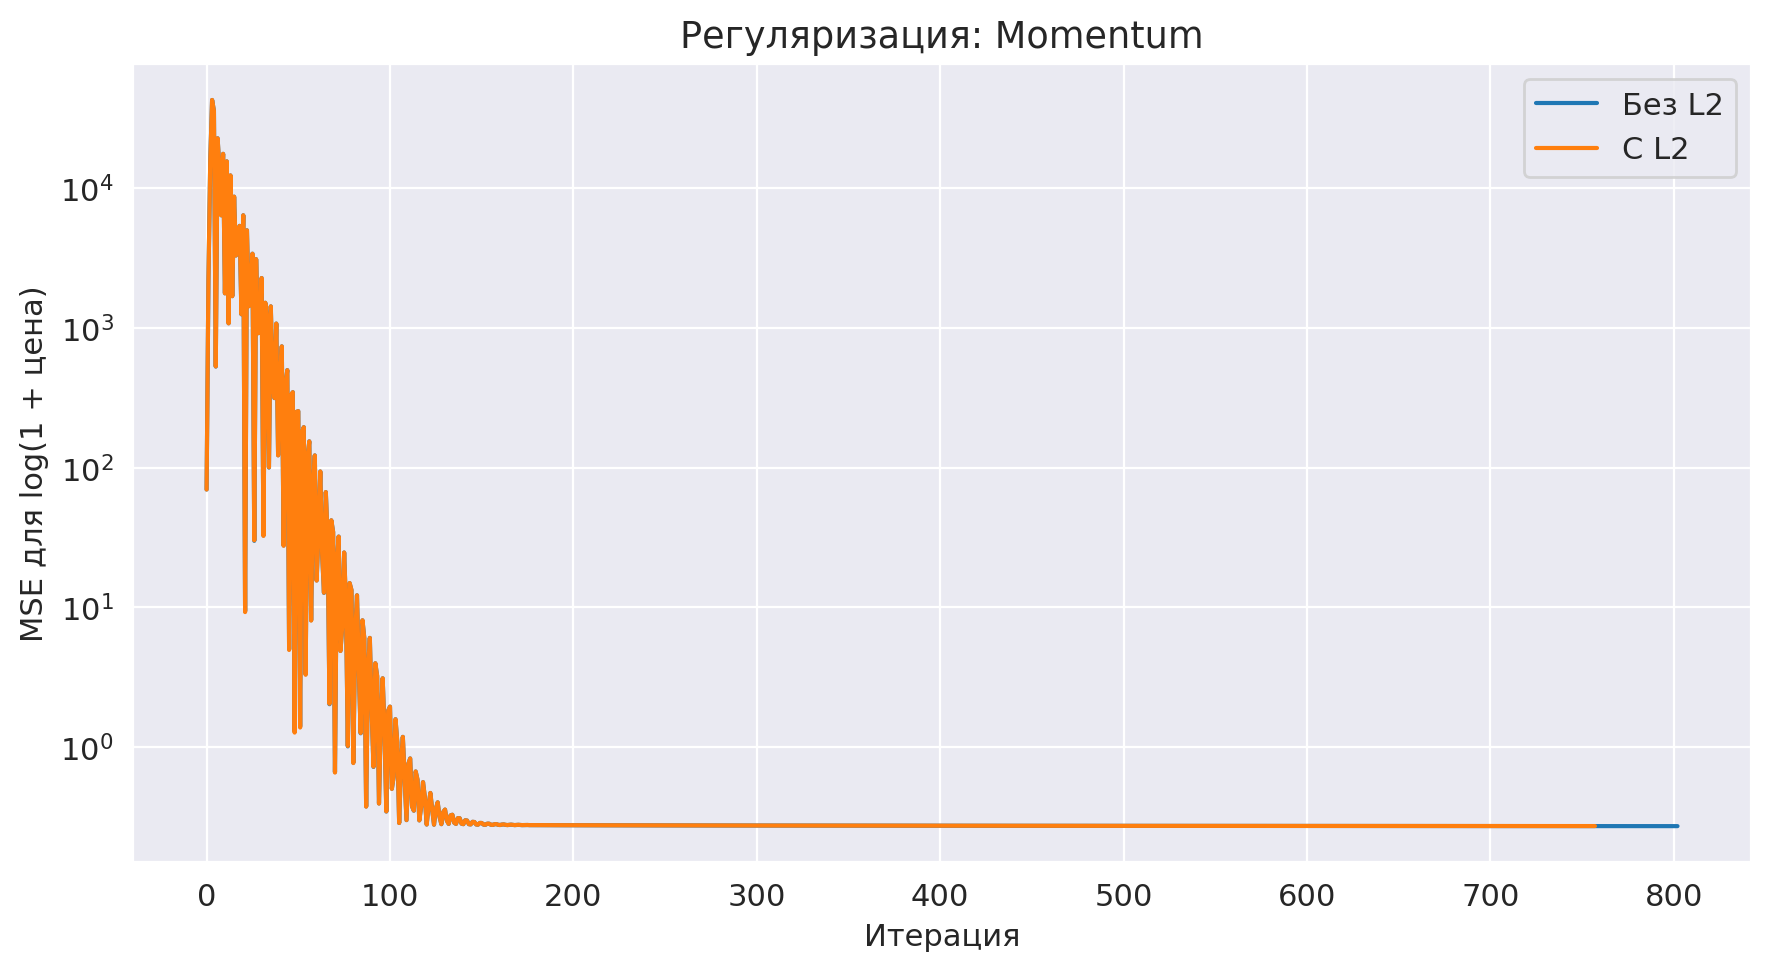

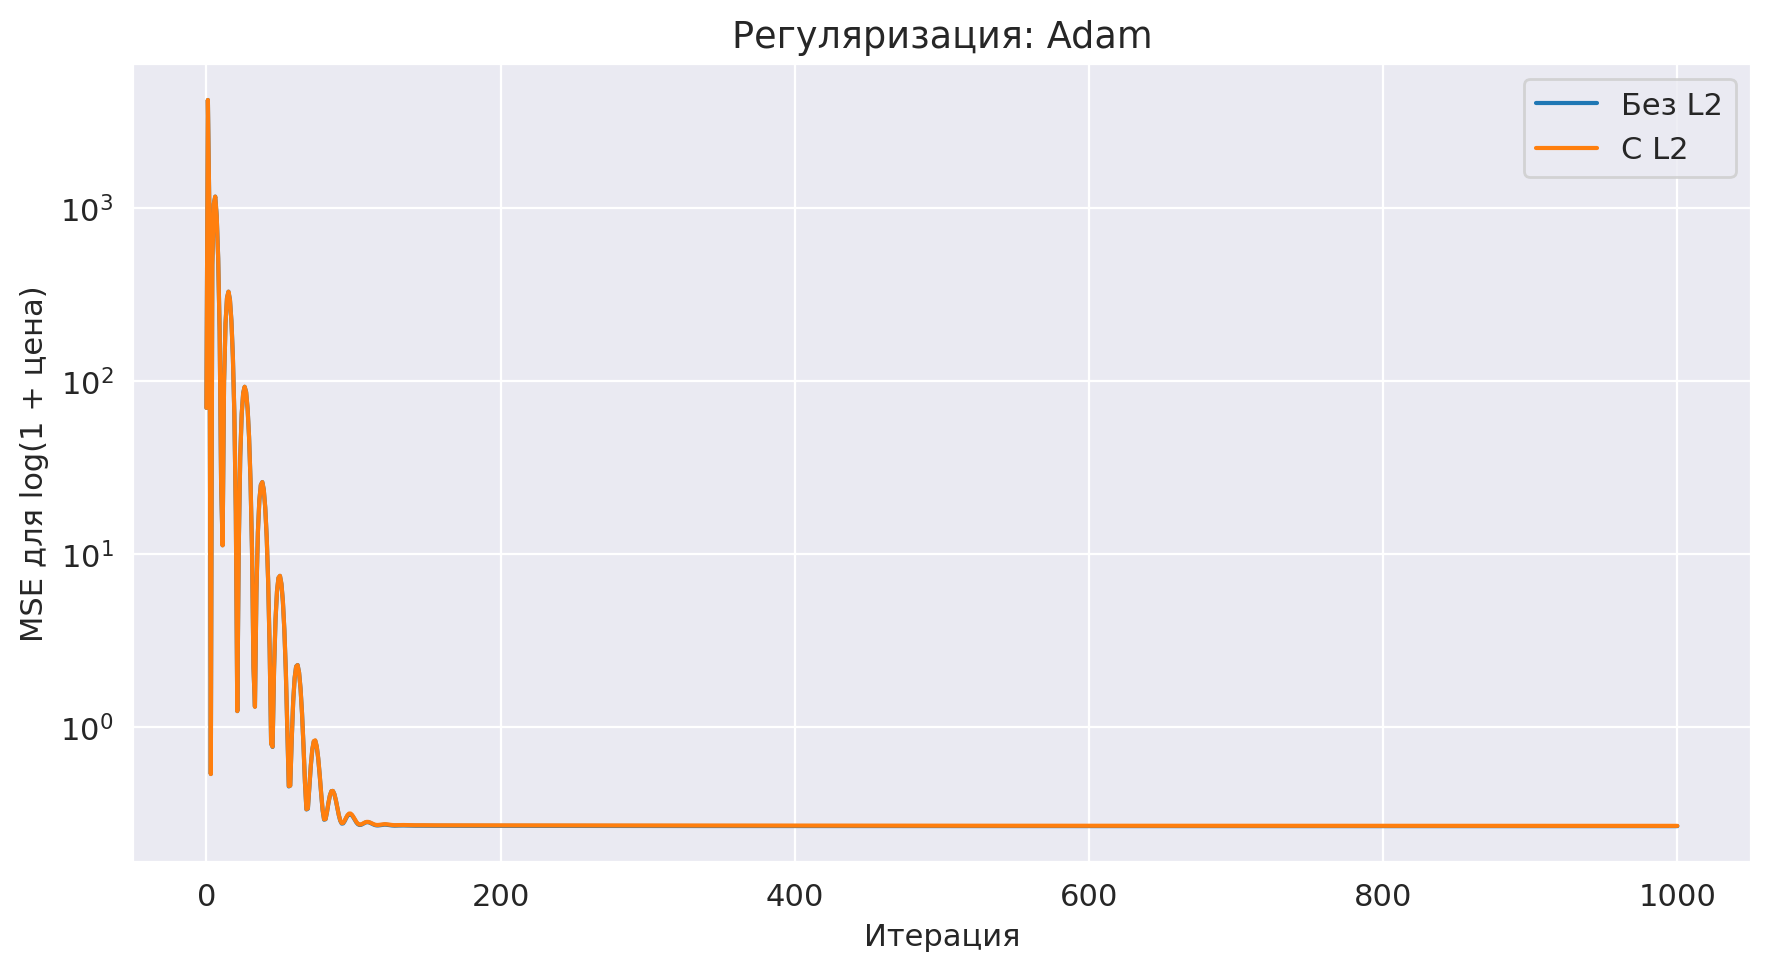

,train_mse_change,test_mse_change,test_r2_change,iterations_without_l2,iterations_with_l2
method,,,,,
Vanilla,0.000081,0.000078,-0.000063,394,392
SGD,0.000035,0.000035,-0.000028,792,792
SAG,-0.247202,-0.249429,0.200822,1000,1000
Momentum,0.000302,0.000336,-0.000270,802,757
Adam,0.000987,0.000763,-0.000615,1000,1000


In [20]:
mu_grid = np.logspace(-4, -1, 3)
regularized_models = {}
regularized_rows = []
regularization_search_rows = []

for method, optimizer_class in optimizer_classes.items():
    best_score = np.inf
    best_model = None
    for lambda_ in lambda_grid:
        for mu in mu_grid:
            loss = L2Regularization(MSELoss(), mu_rate=mu)
            model, elapsed = fit_model(optimizer_class, lambda_, loss_function=loss)
            score = validation_mse(model)
            regularization_search_rows.append({
                'method': method, 'lambda': lambda_, 'mu': mu, 'val_mse': score
            })
            if score < best_score:
                best_score = score
                best_model = model
                best_lambda = lambda_
                best_mu = mu
                best_elapsed = elapsed
    if best_model is None:
        raise ValueError('Не найдены устойчивые параметры для ' + method)
    regularized_models[method] = best_model
    row = model_metrics(best_model, method, best_lambda, best_elapsed)
    row['mu'] = best_mu
    regularized_rows.append(row)
    print(method, 'lambda:', best_lambda, 'mu:', best_mu)

regularization_search = pd.DataFrame(regularization_search_rows)
regularized_results = pd.DataFrame(regularized_rows).set_index('method')
display(pd.concat({'Без L2': baseline_results, 'С L2': regularized_results}, names=['Регуляризация']))

for method in optimizer_classes:
    model = regularized_models[method]
    mu = regularized_results.loc[method, 'mu']
    mse_history = np.asarray(model.loss_history) - mu / 2 * np.asarray(model.weight_norm_history)
    plt.figure()
    plt.plot(best_models[method].loss_history, label='Без L2')
    plt.plot(np.maximum(mse_history, 0), label='С L2')
    plt.xlabel('Итерация')
    plt.ylabel('MSE для log(1 + цена)')
    plt.title('Регуляризация: ' + method)
    plt.yscale('log')
    plt.legend()
    plt.tight_layout()
    plt.show()

regularization_comparison = pd.DataFrame({
    'train_mse_change': regularized_results['train_mse'] - baseline_results['train_mse'],
    'test_mse_change': regularized_results['test_mse'] - baseline_results['test_mse'],
    'test_r2_change': regularized_results['test_r2'] - baseline_results['test_r2'],
    'iterations_without_l2': baseline_results['iterations'],
    'iterations_with_l2': regularized_results['iterations']
})
display(regularization_comparison)

**Вывод:** L2 снизила test MSE SAG с 1.549 до 1.300; у остальных методов train и test MSE немного выросли. У SAG ещё не выполнен критерий сходимости, поэтому улучшение связано с ходом оптимизации. Momentum остановился раньше: 757 шагов вместо 802; общего ускорения нет. Близкие ошибки train и test показывают, что выраженного переобучения здесь не было.

## Задание 8. Альтернативные функции потерь (1 балл)

В этом задании вам предстоит использовать другую функцию потерь для нашей задачи регрессии. В качестве функции потерь мы выбрали **LogCosh** и **HuberLoss**:

$$
    L(y, a)
    =
    \log\left(\cosh(a - y)\right).
$$

$$
L_{\text{Huber}}(y, a) = \frac{1}{n} \sum_{i=1}^{n}
\begin{cases}
   \frac{1}{2} (a_i - y_i)^2, & \text{если } |a_i - y_i| < \delta, \\
   \delta \cdot |a_i - y_i| - \frac{1}{2} \delta^2, & \text{если } |a_i - y_i| \geq \delta,
\end{cases}
$$

**Решение:**

Пусть $r_i=x_i^Tw-y_i$.

Для LogCosh:
$$\frac{d}{dr}\log\cosh r=\frac{\sinh r}{\cosh r}=\tanh r,$$
$$\nabla_w L=\frac1n\sum_i x_i\tanh r_i=\frac1nX^T\tanh(Xw-y).$$

Для Huber:
$$\frac{d}{dr}\frac{r^2}{2}=r,\qquad
\frac{d}{dr}\left(\delta|r|-\frac{\delta^2}{2}\right)=\delta\operatorname{sign}(r),$$
$$\psi_\delta(r)=\begin{cases}r,&|r|\leq\delta,\\\delta\operatorname{sign}(r),&|r|>\delta,\end{cases}$$
$$\nabla_w L=\frac1nX^T\psi_\delta(Xw-y).$$

В точках $r=\pm\delta$ производные обеих ветвей совпадают.

Программно реализуйте функции потерь и их градиенты для LogCosh и HuberLoss в файле `linear_regression.py`. После этого обучите все пять методов градиентного спуска (без регуляризации) с этими лоссами аналогично заданию 5 и сравните качество с результатами из задания 5, где использовался MSE.

Имплементировать эти функции потерь необходимо при помощи наследования от `linear_regression.LossFunction` и имплементирования всех абстрактных методов. Аналитическое решение для этих функций выводить и имплементировать не требуется.



LogCosh Vanilla лучший шаг: 10.0


LogCosh SGD лучший шаг: 10.0


LogCosh SAG лучший шаг: 10.0


LogCosh Momentum лучший шаг: 10.0


LogCosh Adam лучший шаг: 1.0


Huber Vanilla лучший шаг: 10.0


Huber SGD лучший шаг: 10.0


Huber SAG лучший шаг: 10.0


Huber Momentum лучший шаг: 10.0


Huber Adam лучший шаг: 1.0


lambda  train_mse   val_mse  test_mse  train_r2   test_r2  \
loss    method                                                                
Huber   Adam         1.0   0.276953  0.279044  0.276195  0.778633  0.777628   
        Momentum    10.0   0.279097  0.279705  0.278743  0.776919  0.775576   
        SAG         10.0   1.300091  1.304462  1.296698 -0.039156 -0.044009   
        SGD         10.0   0.301793  0.302866  0.301912  0.758778  0.756922   
        Vanilla     10.0   0.292773  0.291812  0.293368  0.765988  0.763801   
LogCosh Adam         1.0   0.275705  0.277916  0.274863  0.779631  0.778700   
        Momentum    10.0   0.278997  0.279333  0.278731  0.776999  0.775585   
        SAG         10.0   0.992469  0.993800  0.989909  0.206725  0.202996   
        SGD         10.0   0.300176  0.301348  0.300238  0.760071  0.758270   
        Vanilla     10.0   0.292247  0.291440  0.292781  0.766409  0.764274   
MSE     Adam        10.0   0.266414  0.269228  0.265360  0.787057  0.786351   
        Momentum     1.0   0.271493  0.273150  0.271067  0.782997  0.781756   
        SAG          1.0   1.552019  1.541129  1.549302 -0.240520 -0.247388   
        SGD          0.1   0.359815  0.361362  0.359498  0.712402  0.710558   
        Vanilla      1.0   0.295300  0.295655  0.295220  0.763968  0.762310   

                  iterations stop_reason    seconds  
loss    method                                       
Huber   Adam            1000    max_iter   8.731445  
        Momentum        1000    max_iter   8.624010  
        SAG             1000    max_iter   5.063363  
        SGD             1000    max_iter   3.786863  
        Vanilla          880   tolerance   7.664235  
LogCosh Adam            1000    max_iter  15.246925  
        Momentum        1000    max_iter  15.059645  
        SAG             1000    max_iter   7.282899  
        SGD             1000    max_iter   8.055440  
        Vanilla          805   tolerance  12.946073  
MSE     Adam            1000    max_iter   8.764111  
        Momentum         802   tolerance   6.559960  
        SAG             1000    max_iter   3.840730  
        SGD              792   tolerance   2.577346  
        Vanilla          394   tolerance   3.250091

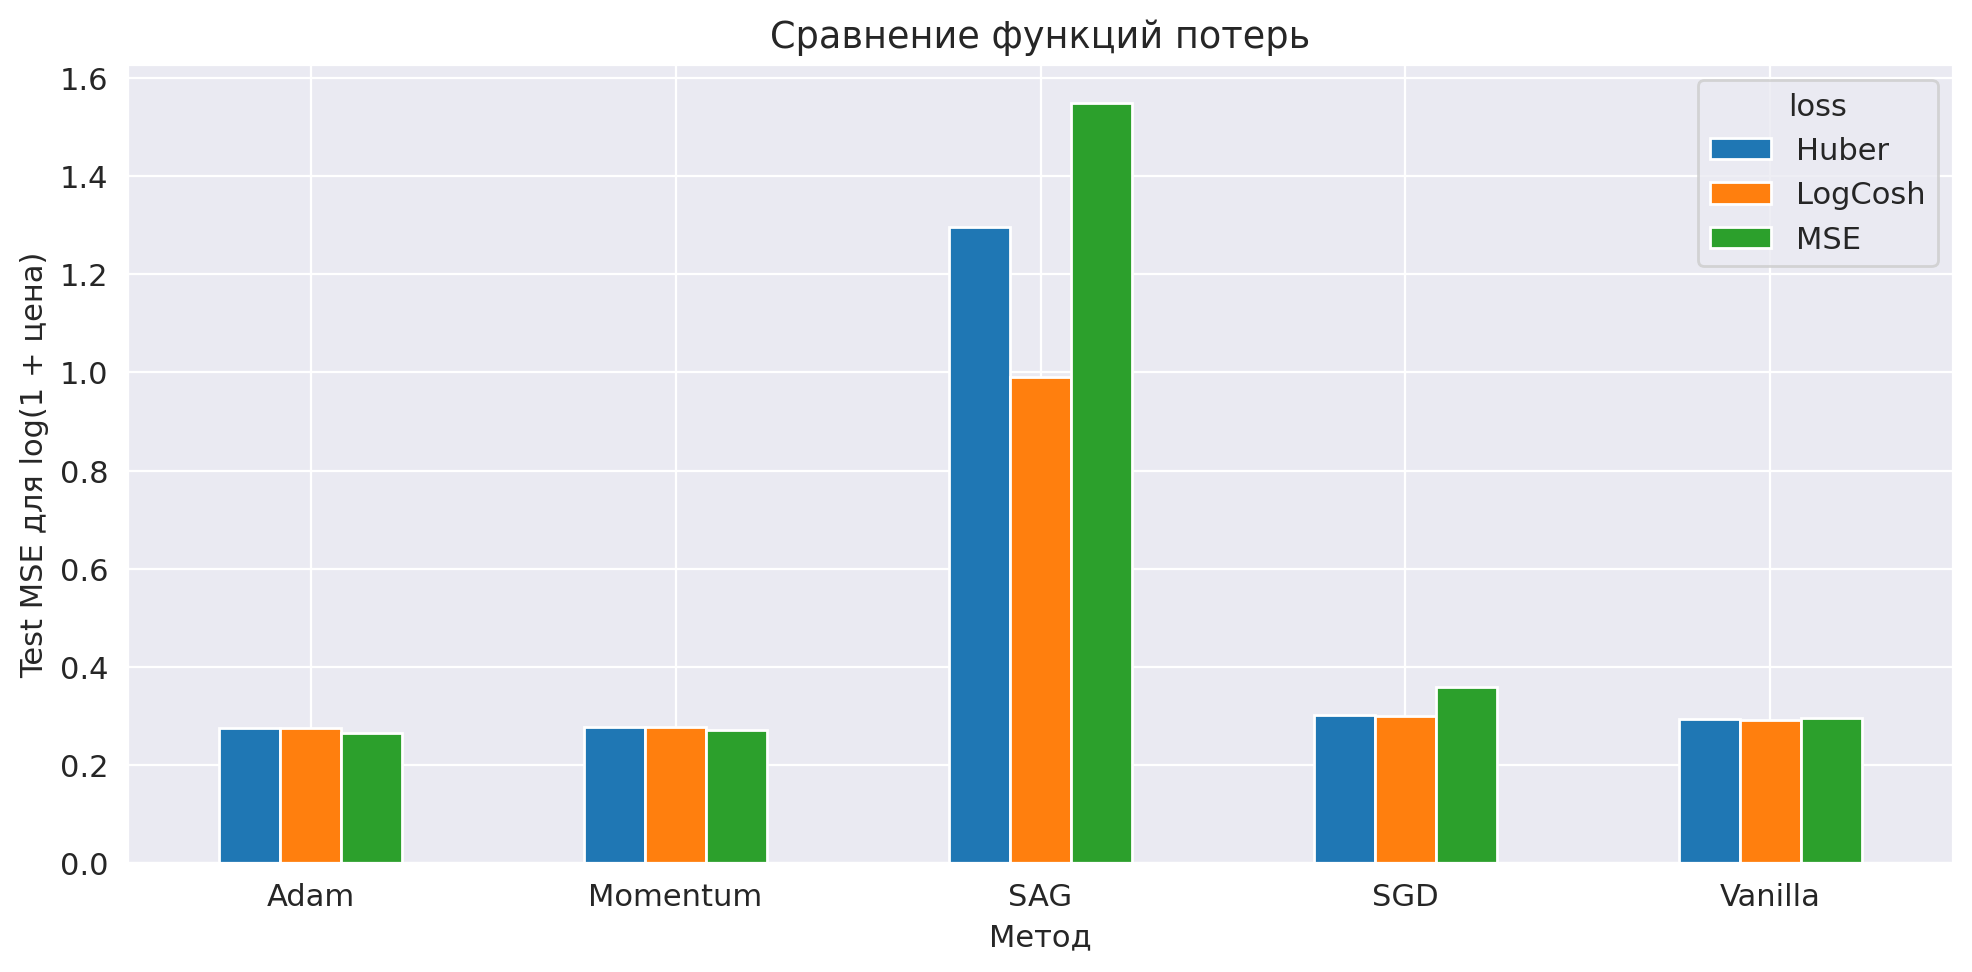

Лучший loss по validation MSE для каждого метода:


,method,loss,lambda,val_mse,test_mse
10,Adam,MSE,10.0,0.269228,0.265360
11,Momentum,MSE,1.0,0.273150,0.271067
7,SAG,LogCosh,10.0,0.993800,0.989909
8,SGD,LogCosh,10.0,0.301348,0.300238
9,Vanilla,LogCosh,10.0,0.291440,0.292781


In [21]:
alternative_losses = {'LogCosh': LogCoshLoss, 'Huber': HuberLoss}
alternative_rows = []
alternative_models = {}

for loss_name, loss_class in alternative_losses.items():
    for method, optimizer_class in optimizer_classes.items():
        best_score = np.inf
        best_model = None
        for lambda_ in lambda_grid:
            model, elapsed = fit_model(optimizer_class, lambda_, loss_function=loss_class())
            score = validation_mse(model)
            if score < best_score:
                best_score = score
                best_model = model
                best_lambda = lambda_
                best_elapsed = elapsed
        if best_model is None:
            raise ValueError('Не найдены устойчивые параметры: ' + loss_name + ', ' + method)
        alternative_models[(loss_name, method)] = best_model
        row = model_metrics(best_model, method, best_lambda, best_elapsed)
        row['loss'] = loss_name
        alternative_rows.append(row)
        print(loss_name, method, 'лучший шаг:', best_lambda)

alternative_results = pd.DataFrame(alternative_rows).set_index(['loss', 'method'])
mse_results = baseline_results.reset_index()
mse_results['loss'] = 'MSE'
mse_results = mse_results.set_index(['loss', 'method'])
loss_comparison = pd.concat([mse_results, alternative_results]).sort_index()
display(loss_comparison)

comparison = loss_comparison['test_mse'].unstack('loss')
comparison.plot.bar(figsize=(10, 5))
plt.xlabel('Метод')
plt.ylabel('Test MSE для log(1 + цена)')
plt.title('Сравнение функций потерь')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print('Лучший loss по validation MSE для каждого метода:')
display(loss_comparison.reset_index().loc[
    loss_comparison.reset_index().groupby('method')['val_mse'].idxmin(),
    ['method', 'loss', 'lambda', 'val_mse', 'test_mse']
])

**Вывод:** LogCosh улучшил Vanilla, SGD и SAG, а у Adam и Momentum лучшим остался MSE. Общий лучший результат получил Adam с MSE: test R² около 0.786. LogCosh и Huber уменьшают влияние больших остатков, но это не гарантирует минимальный MSE; многие модели ещё ограничены лимитом итераций.